<a href="https://colab.research.google.com/github/daryamraeva/BigData_MGPU/blob/main/%D0%A1%D0%A6%D0%A2%20%D0%9B%D0%912.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа № 2 — ЭТАЛОННОЕ РЕШЕНИЕ

## Виртуальные сенсоры и IoT-телеметрия робототехнической системы

**Раздел дисциплины:** «Интернет вещей»

**Формат:**  Jupyter Notebook / Google Colab

**Среда:** Python 3.10+ · NumPy, Pandas, Matplotlib

**Максимум:** 20 баллов

---

### Цель работы

Смоделировать получение сенсорных данных робототехнической системой и сформировать
воспроизводимый виртуальный IoT-канал телеметрии без физического оборудования.

### Что готово, а что пишет студент

| Готовое | Реализация студента |
|---|---|
| кинематика робота `DiffDrive` из `robotics-course` | модели трёх виртуальных датчиков |
| код построения графиков | формирование сообщений телеметрии |
| формулы параметров варианта | модель канала: потери, задержка, джиттер |
| — | метрики качества канала и восстановления |

### Критерии оценки — 20 баллов

| Часть | Содержание | Баллы |
|---|---|---|
| 1 | Модель физического процесса и виртуальные датчики | 5 |
| 2 | Телеметрия в формате сообщений и модель канала | 5 |
| 3 | Метрики качества телеметрии (обязательный минимум) | 2 |
| 4 | Графики: исходный и принятый ряды, ошибка, актуальность | 3 |
| 5 | Исследование влияния потерь и частоты, вывод | 3 |
| 6 | **Методическое задание:** фрагмент урока или игра для школьников по одному из выводов работы | 2 |

> Часть 6 добавлена за счёт части 3: в обязательный минимум метрик входят
> четыре (фактическая частота, доля потерь, ошибка датчика, ошибка у потребителя), остальные
> (серии потерь, разрывы, возраст данных) остаются в эталоне как расширенный уровень.

### Материалы

* Каталог мобильных роботов (кинематика робота — источник «физики» процесса) —
  <https://github.com/BosenkoTM/robotics-course/tree/2026/04-mobile-robots>
* Каталог perception (модели датчиков) —
  <https://github.com/BosenkoTM/robotics-course/tree/2026/05-perception>

> ### ВАРИАНТ ПРЕПОДАВАТЕЛЯ
> Эталонный прогон — **вариант 13**
> (`Encoder+IMU`, 20 Гц, шум 1,5 %, потери 5 %). В конце ноутбука приведена сводка по всем
> 25 вариантам: решение проверено на каждом из них. Вариант для студентов отличается только
> содержимым кодовых ячеек и номером варианта.

---

# Смысл работы для будущего учителя


Любой школьный проект с датчиками — метеостанция, «умная теплица», робот на соревнованиях,
датчик СО₂ в классе — устроен одинаково: **датчик измеряет → данные передаются → человек или
программа видит результат**. На каждом звене данные деградируют:

* датчик **врёт** — у него есть шум и смещение нуля;
* канал **теряет** и **задерживает** сообщения;
* экран показывает **последнее пришедшее** значение, а не то, что происходит прямо сейчас.

Работа учит **измерять**, сколько теряется на каждом звене, — и делает это без единого робота:
физика движения, датчики и связь смоделированы в Python. Поэтому эксперимент воспроизводим у всех студентов одинаково, а потери и шум — «покрутить», чего на реальном оборудовании
сделать нельзя.

### Одна главная мысль

**То, что видит пользователь, ≠ то, что измерил датчик ≠ то, что было на самом деле.**
В работе это три числа, и все три посчитаны:

| Что сравниваем | Название в ноутбуке | Вариант 13 (энкодер) |
|---|---|---:|
| датчик и окружение | `sensor_rmse` | 0,0147 м/с |
| экран пользователя и окружение | `recon_rmse` | 0,0176 м/с |
| насколько устарели данные на экране | `aoi_mean_s` | 23–37 мс (см. п. 4.1) |

Разница между первыми двумя строками — вклад **передачи данных**, а не датчика. Этот
вывод понятен и девятикласснику, и он же лежит в основе всей промышленной телеметрии.

### Три вывода работы на языке урока

1. **Шум частотой не лечится.** Как часто ни опрашивай датчик, его собственная погрешность
   остаётся той же (0,0145–0,0152 м/с при любой частоте от 5 до 50 Гц).
2. **Потери на медленном сигнале бьют по свежести, а не по точности.** Пропущенное сообщение
   почти не портит значение, но делает его устаревшим.
3. **«Чаще» — не всегда «лучше».** Есть точка насыщения (здесь 20–25 Гц), после которой рост
   частоты только расходует канал связи и батарейку.

### Что это даёт учителю информатики и робототехники

| Ситуация в школе | Что даёт работа |
|---|---|
| Показания в проекте «скачут», и ученики думают, что датчик сломан | язык для объяснения: шум, смещение, разброс; умение отличить неисправность от нормы |
| Данные на экране «застывают» или приходят рывками | понимание потерь и задержек, а значит — как настроить частоту отправки |
| Нет комплекта роботов на каждого ученика | готовая виртуальная лаборатория, которая работает в браузере |
| Требуется тема для исследовательского проекта | готовая постановка: «как часто надо отправлять данные?» с измеримым ответом |
| Требуется связать информатику с физикой и статистикой | измерения и погрешность, вероятность и частота, среднее и разброс — на одном примере |

Раздел «Методический перенос в школу» в конце ноутбука показывает, как упростить работу до
урока в 7–11 классах и кружка робототехники. На его основе выполняется **часть 6** —
небольшое методическое задание: фрагмент урока или игра для школьников по одному из трёх
выводов работы.

### Как читать ноутбук

Каждая кодовая ячейка сопровождается блоками **«Разбор ячейки»** (что делает код) и
**«Что получено»** (что означают числа). Блоки **«Преподавателю»** адресованы ведущему
лабораторную работу в вузе. Ячейки с пометкой **«Дополнительная ячейка»** добавлены к
эталону: они проверяют выводы на серии прогонов и уточняют расчёт возраста данных.

---

# Теоретическое введение

> Раздел добавлен для самостоятельной подготовки: он объясняет, **почему** работа устроена
> именно так. Преподавателю служит планом разбора на занятии, студенту — минимумом, без
> которого код ниже выглядит набором формул.

## 1. Что моделируется и зачем

Робот на площадке — это **IoT-устройство**: он измеряет физические величины и отправляет их
наружу. Типовая цепочка выглядит так:

```text
физический процесс → датчик → микроконтроллер → канал связи → брокер → потребитель
   (движение)      (шум,     (частота,           (потери,     (MQTT,   (мониторинг,
                  квантование)  временные метки)   задержки)    Kafka)   управление)
```

Каждое звено **портит** данные по-своему, и задача работы — измерить, сколько именно теряется
на каждом шаге. Мы моделируем всю цепочку локально, без ESP32 и без брокера: физический
процесс заменён кинематической моделью, а публикация и приём сообщений — функциями Python.
Это стандартная практика: логику телеметрии отлаживают на модели, потому что на железе
воспроизвести конкретную последовательность потерь невозможно.

### Немного про MQTT

Промышленный стандарт для такой телеметрии — протокол **MQTT**: устройство *публикует*
сообщения в *топик* (например, `robot01/imu`), а потребители *подписываются* на него.
Предусмотрены три уровня гарантии доставки:

| QoS | Гарантия | Что это значит для данных |
|---|---|---|
| **0** | «не более одного раза» | пакет может пропасть, повторов нет |
| **1** | «хотя бы один раз» | потерь нет, но возможны дубликаты |
| **2** | «ровно один раз» | нет ни потерь, ни дубликатов, максимальная задержка |

В работе моделируется **QoS 0** — самый распространённый режим для телеметрии высокой
частоты: потеря отдельного отсчёта дешевле, чем задержка на подтверждение. Именно поэтому
в задании и появляется параметр «процент потерь».

## 2. Модель измерения

Показание датчика связано с истинной величиной так:

$$y_k = h(x_k) + b_k + n_k, \qquad n_k \sim \mathcal{N}(0, \sigma^2)$$

где $h$ — уравнение измерения, $b_k$ — систематическая составляющая (смещение нуля, дрейф),
$n_k$ — случайный шум. Различать эти две составляющие принципиально: шум подавляется
усреднением, **смещение — нет**, его нужно калибровать.

| Датчик | Что измеряет | Основные искажения |
|---|---|---|
| **Энкодер** | углы поворота колёс → линейная скорость | **квантование** по числу импульсов на оборот, пропуск импульсов на высокой скорости |
| **IMU (гироскоп)** | угловая скорость | белый шум + **дрейф нуля** (случайное блуждание), температурная зависимость |
| **LiDAR** | дальность до препятствия | шум дальности, **выпадение отсчётов** (dropout) на тёмных и зеркальных поверхностях |

### «Шум 1,5 %» — процент от чего?

В таблице вариантов уровень шума задан в процентах, и это типичная формулировка из паспорта
датчика: процент берётся **от полной шкалы** (full scale), а не от текущего значения. В работе
шкалы заданы явно: энкодер 1,0 м/с, гироскоп 2,0 рад/с, дальномер 5,0 м. Отсюда
$\sigma = \text{noise\_pct} / 100 \cdot \text{scale}$. Студент, посчитавший шум в процентах от
измеряемого значения, получит другую (и тоже осмысленную) модель — но тогда это надо
оговорить в отчёте.

## 3. Дискретизация во времени

Датчик опрашивается с частотой $f$ (период $T = 1/f$). Теорема Котельникова требует
$f > 2 f_{\max}$, где $f_{\max}$ — верхняя частота полезного сигнала. Наш сигнал медленный
(манёвры робота — доли герца), поэтому даже 5 Гц формально достаточно; но **точность
восстановления** между отсчётами всё равно падает, и это видно в исследовании части 5.

Важное различие двух временных меток:

* `timestamp` — момент **измерения**, проставляется устройством; именно он нужен для анализа
  данных;
* время **приёма** (`t_rx`) — когда сообщение дошло до потребителя; разность между ними и
  есть задержка доставки.

Разброс задержки называется **джиттером**. Если потребитель ошибочно считает временем
измерения момент приёма, джиттер превращается в ошибку измерения — классическая ошибка
проектирования телеметрии.

## 4. Модель канала

Три эффекта, которые моделируются:

1. **Потери.** Каждое сообщение теряется независимо с вероятностью $p$ (схема Бернулли).
   В реальных сетях потери группируются в **серии** (замирание сигнала, уход робота за
   препятствие); классическая модель этого — двухсостоянийная цепь Гилберта — Эллиота.
   В нашем канале длина серии задаётся параметром `burst_len`.
2. **Задержка и джиттер.** Базовая задержка плюс случайная добавка с экспоненциальным
   хвостом: редкие, но большие задержки — типичный профиль беспроводной сети.
3. **Возможное переупорядочивание.** Из-за разного джиттера сообщение может прийти раньше
   отправленного до него; приёмник сортирует по времени прибытия.

**Зачем нужен `seq`.** Сквозной номер сообщения — единственный способ обнаружить потерю на
приёмной стороне: разрыв в нумерации означает, что пакет не дошёл. Без `seq` потребитель
видит просто разрежённый поток и не может отличить потерю от того, что устройство ничего не
отправляло.

## 5. Как оценивают качество телеметрии

| Метрика | Смысл | Как читать |
|---|---|---|
| **PDR** (packet delivery ratio) | доля доставленных сообщений | 95 % при заданных 5 % потерь — норма |
| `rate_actual_hz` | фактическая частота приёма | всегда ниже номинальной при потерях |
| `longest_loss_burst` | самая длинная серия подряд потерянных пакетов | опаснее средних потерь |
| `max_gap_s` | максимальный разрыв в данных | сколько времени потребитель «слепой» |
| `jitter_ms` | разброс задержки доставки | влияет на управление в реальном времени |
| `sensor_rmse` | ошибка самого датчика | нижняя граница качества |
| `recon_rmse` | ошибка сигнала **у потребителя** | включает и шум, и устаревание данных |
| **AoI** (age of information) | возраст последних имеющихся данных | ключевая метрика IoT последних лет |

### Восстановление сигнала: ZOH

Потребитель видит не непрерывный сигнал, а редкие отсчёты. До прихода следующего сообщения
он вынужден считать величину неизменной — это **экстраполяция нуль-порядка** (zero-order
hold, ZOH), она же «ступеньки» на графике. Отсюда важное неравенство:

$$\text{recon\_rmse} \;\ge\; \text{sensor\_rmse}$$

Разница между ними — это цена дискретизации и потерь, то есть вклад **канала**, а не датчика.

### Age of Information

$$\Delta(t) = t - u(t)$$

где $u(t)$ — момент формирования самого свежего из полученных к моменту $t$ сообщений.
График AoI — пила: линейно растёт между приёмами и падает при каждом новом сообщении.
Метрика появилась именно из задач IoT и управления: для контура обратной связи важна не
пропускная способность, а **свежесть** данных. Канал может доставлять много сообщений и при
этом иметь плохой AoI, если доставка идёт пачками с большими паузами.

## 6. Что сознательно упрощено

1. **Нет реального брокера и сети.** Потери и задержки заданы вероятностной моделью, а не
   получены из стека TCP/IP.
2. **Часы идеальны.** Устройство и потребитель используют одну шкалу времени; в реальности
   расхождение часов (clock drift) — отдельная проблема, решаемая NTP/PTP.
3. **Нет подтверждений и повторов.** Моделируется QoS 0; при QoS 1 картина потерь была бы
   иной, но выросла бы задержка.
4. **Датчики независимы.** Реальные энкодер и IMU коррелируют через общую вибрацию и
   питание.
5. **Нет ограничения по энергии.** У автономного устройства частота публикации ограничена
   в первую очередь батареей, а не каналом.

## 7. Обозначения и параметры

| Обозначение | Смысл | Значение |
|---|---|---|
| `SIM_TIME` | длительность эксперимента | 40 с (по заданию не менее 30) |
| `DT_TRUTH` | шаг «физической» модели | 0,001 с (1 кГц) |
| `freq_hz` | частота публикации телеметрии | по варианту, 5…50 Гц |
| `noise_pct` | уровень шума от полной шкалы | по варианту, 0,5…2,5 % |
| `loss_pct` | вероятность потери сообщения | по варианту, 0…10 % |
| `SCALE` | полные шкалы датчиков | 1,0 м/с · 2,0 рад/с · 5,0 м |
| `ENCODER_CPR` | импульсов на оборот вала | 1024, квадратура ×4 |
| `IMU_BIAS_WALK` | случайное блуждание нуля гироскопа | 0,002 рад/с за секунду |
| `seed` | зерно генератора | `200 + номер варианта` |

---

---
## Задание 0. Вариант и среда

**Разбор ячейки.** Параметры варианта вычисляются формулой, а не берутся из таблицы
вручную. Схема та же, что в таблице задания: `(n−1) % 5` выбирает **сенсор** и **уровень
шума**, `(n−1) // 5` — **частоту** и **долю потерь**. Получается матрица 5×5, где каждая пара
«сенсор — частота» встречается ровно один раз. Поле `seed` делает прогон воспроизводимым:
при повторном запуске последовательность шума и потерь будет та же.

In [1]:
# =========== ЭТАЛОННЫЙ ПРОГОН ===========
STUDENT_NAME  = "МРАЕВА ДАРЬЯ"
STUDENT_GROUP = "ИНДОР-221"
VARIANT       = 8
# ========================================

assert 1 <= VARIANT <= 25, "Вариант — целое число от 1 до 25"


def variant_params(n: int) -> dict:
    """Параметры варианта по таблице задания."""
    sensors = ["Encoder", "IMU", "Encoder+IMU", "LiDAR", "Encoder+LiDAR"]
    freqs   = [5, 10, 20, 25, 50]
    losses  = [0, 2, 5, 8, 10]
    noises  = [0.5, 1.0, 1.5, 2.0, 2.5]
    return {
        "sensor":    sensors[(n - 1) % 5],
        "freq_hz":   freqs[(n - 1) // 5],
        "noise_pct": noises[(n - 1) % 5],
        "loss_pct":  losses[(n - 1) // 5],
        "seed":      200 + n,
    }


cfg = variant_params(VARIANT)
print(f"Студент : {STUDENT_NAME}, группа {STUDENT_GROUP}")
print(f"Вариант : {VARIANT}")
for k, v in cfg.items():
    print(f"  {k:<10}: {v}")

Студент : МРАЕВА ДАРЬЯ, группа ИНДОР-221
Вариант : 8
  sensor    : Encoder+IMU
  freq_hz   : 10
  noise_pct : 1.5
  loss_pct  : 2
  seed      : 208


**Что получено.** Вариант 13: два потока телеметрии (`Encoder+IMU`), частота 20 Гц,
шум 1,5 % от полной шкалы, потери 5 %, зерно 213. Это средний по сложности вариант —
есть и мультиплексирование двух датчиков в один поток, и ненулевые потери.

**Преподавателю.** Проверяется в первую очередь: совпадает ли `VARIANT` с номером студента в
списке и не осталось ли значение по умолчанию в `STUDENT_NAME`. Параметры варианта править
руками нельзя — подгонка `loss_pct` под красивый результат обесценивает часть 5.

**Разбор ячейки.** Репозиторий подключается так же, как в лабораторной № 1: клонируется
ветка `2026` с флагом `--depth 1` (только последний коммит), после чего каталоги
`04-mobile-robots` и `05-perception` добавляются в путь поиска модулей. Из репозитория
берётся кинематика `DiffDrive` — источник «физики» для нашей телеметрии.

Клонирование обёрнуто в `try / except` намеренно: ноутбук должен выполняться и **без сети**.
Если репозиторий недоступен, используется встроенная реализация того же шага Эйлера, и все
дальнейшие результаты не меняются.

In [2]:
from pathlib import Path
import subprocess
import sys

REPO_URL = "https://github.com/BosenkoTM/robotics-course.git"
repo = Path("robotics-course")

if not repo.exists():
    try:
        subprocess.run(["git", "clone", "--depth", "1", "--branch", "2026",
                        REPO_URL, str(repo)], check=True, timeout=180,
                       capture_output=True)
    except Exception as err:                      # нет сети — работаем автономно
        print("Репозиторий не склонирован:", type(err).__name__)

for sub in ("04-mobile-robots", "05-perception"):
    path = (repo / sub).resolve()
    if path.exists():
        sys.path.insert(0, str(path))
        sys.path.insert(0, str(path / "lib"))

DiffDrive = None
try:
    from kinematic_models import DiffDrive          # 04-mobile-robots/lib
except Exception:
    try:
        from lib.kinematic_models import DiffDrive
    except Exception:
        DiffDrive = None

REPO_OK = DiffDrive is not None
print("Репозиторий доступен :", repo.exists())
print("DiffDrive из репозитория:", "да" if REPO_OK else "нет — используется встроенная модель")

Репозиторий доступен : True
DiffDrive из репозитория: да


**Что получено.** В этом прогоне сети не было, поэтому сработал запасной путь: кинематика
считается встроенной функцией `diff_drive_forward`. В Colab с доступом в интернет строка
покажет `DiffDrive из репозитория: да`, и будет использован класс из `robotics-course`.

**Почему результат от этого не меняется.** Обе реализации выполняют один и тот же шаг Эйлера
для дифференциального привода: сдвиг на $v\,\Delta t$ вдоль курса и доворот на
$\omega\,\Delta t$. При шаге 1 мс расхождение траекторий пренебрежимо мало на фоне шума
датчиков, который мы исследуем.

In [3]:
import json
import math
import zipfile
from dataclasses import dataclass
from typing import Callable, Dict, List, Optional, Tuple

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

matplotlib.rcParams["figure.dpi"] = 110
matplotlib.rcParams["font.size"] = 9

# --- параметры эксперимента, единые для всех вариантов
DEVICE_ID  = "robot01"
SIM_TIME   = 40.0        # длительность эксперимента, с (требуется не менее 30)
DT_TRUTH   = 0.001       # шаг «физической» модели, с (1 кГц)
WHEEL_R    = 0.05        # радиус колеса, м
WHEEL_BASE = 0.20        # колея, м

# --- полные шкалы датчиков: относительно них считается уровень шума в процентах
SCALE = {
    "encoder": 1.00,     # м/с   — максимальная линейная скорость
    "imu":     2.00,     # рад/с — полная шкала гироскопа
    "lidar":   5.00,     # м     — максимальная дальность
}
UNITS = {"encoder": "м/с", "imu": "рад/с", "lidar": "м"}

ENCODER_CPR   = 1024     # импульсов на оборот вала
ENCODER_QUAD  = 4        # квадратурное декодирование: x4
IMU_BIAS0     = 0.010    # начальное смещение нуля гироскопа, рад/с
IMU_BIAS_WALK = 0.002    # случайное блуждание смещения, рад/с за секунду
LIDAR_RANGE   = SCALE["lidar"]
LIDAR_DROPOUT = 0.01     # доля недостоверных измерений дальномера

rng = np.random.default_rng(cfg["seed"])

print(f"Длительность эксперимента : {SIM_TIME} с")
print(f"Частота публикации        : {cfg['freq_hz']} Гц "
      f"(период {1000 / cfg['freq_hz']:.1f} мс)")
print(f"Ожидаемое число отсчётов  : {int(SIM_TIME * cfg['freq_hz'])}")
print(f"Датчики варианта          : {cfg['sensor']}")

Длительность эксперимента : 40.0 с
Частота публикации        : 10 Гц (период 100.0 мс)
Ожидаемое число отсчётов  : 400
Датчики варианта          : Encoder+IMU


**Что получено.** Заданы константы эксперимента: 40 с длительности (задание требует не
менее 30), шаг «физической» модели 1 мс, полные шкалы датчиков и параметры их несовершенства.
При 20 Гц ожидается 800 отсчётов на каждый поток.

**На что обратить внимание:**

* `SCALE` — те самые «полные шкалы», от которых считается процент шума. Их надо задать
  явно и один раз: иначе у каждого студента «1,5 % шума» будет означать своё.
* `ENCODER_CPR = 1024` и квадратурное декодирование ×4 дают 4096 импульсов на оборот — типовая
  характеристика инкрементального энкодера среднего класса.
* `IMU_BIAS_WALK` задаёт дрейф нуля гироскопа. Именно он, а не белый шум, ограничивает
  точность интегрирования угловой скорости на длинных интервалах.
* `rng = np.random.default_rng(cfg["seed"])` — **единственный** источник случайности в
  работе. Все датчики и канал берут числа из него, поэтому прогон полностью воспроизводим.

---
# Часть 1. Модель процесса и виртуальные датчики (5 баллов)

## 1.1. Физический процесс

Телеметрия должна что-то измерять, поэтому сначала нужен процесс. Берём робота из
лабораторной № 1: дифференциальный привод, кинематика `DiffDrive` из `robotics-course`.
Робот едет по заданной программе — разгон, повороты в обе стороны, змейка, торможение —
чтобы в сигнале были и участки постоянной скорости, и быстрые изменения. На постоянных
участках хорошо видно шум датчика, на быстрых — потери из-за низкой частоты опроса.

Модель считается с шагом 1 мс, то есть в 20–200 раз чаще, чем публикуется телеметрия. Это
намеренно: результат такой модели мы считаем **истиной** (ground truth), с которой потом
сравниваем и измерения, и то, что дошло до получателя.

In [4]:
def control_profile(t: float) -> Tuple[float, float]:
    """Программа движения робота: (линейная скорость, угловая скорость) в момент t."""
    if t < 8.0:
        return 0.60, 0.00                    # разгон и прямолинейный участок
    if t < 14.0:
        return 0.45, 0.55                    # поворот влево
    if t < 22.0:
        return 0.70, 0.00                    # быстрый прямой участок
    if t < 28.0:
        return 0.40, -0.70                   # поворот вправо
    if t < 34.0:
        return 0.55, 0.25 * math.sin(0.9 * t)  # плавная змейка
    return 0.20, 0.00                        # торможение перед остановкой


def diff_drive_forward(pose: np.ndarray, v: float, omega: float, dt: float) -> np.ndarray:
    """Шаг кинематики дифференциального привода (метод Эйлера)."""
    x, y, th = pose
    return np.array([x + v * math.cos(th) * dt,
                     y + v * math.sin(th) * dt,
                     th + omega * dt])


robot = DiffDrive(wheel_radius=WHEEL_R, wheel_base=WHEEL_BASE) if REPO_OK else None
step = (lambda p, v, w, dt: robot.forward(p, v, w, dt)) if REPO_OK else diff_drive_forward

n_truth = int(SIM_TIME / DT_TRUTH) + 1
pose = np.array([0.5, 0.5, 0.0])
rows = []
for k in range(n_truth):
    t = k * DT_TRUTH
    v, omega = control_profile(t)
    rows.append({"t": t, "x": pose[0], "y": pose[1], "theta": pose[2],
                 "v": v, "omega": omega,
                 "w_right": (v + omega * WHEEL_BASE / 2) / WHEEL_R,
                 "w_left":  (v - omega * WHEEL_BASE / 2) / WHEEL_R})
    pose = step(pose, v, omega, DT_TRUTH)

truth = pd.DataFrame(rows)

print(f"Эталонная траектория: {len(truth)} точек с шагом {DT_TRUTH * 1000:.0f} мс")
print(f"Пройденный путь     : {float(truth['v'].sum() * DT_TRUTH):.2f} м")
print(f"Диапазон v          : {truth['v'].min():.2f} … {truth['v'].max():.2f} м/с")
print(f"Диапазон omega      : {truth['omega'].min():.2f} … {truth['omega'].max():.2f} рад/с")
truth.head(3)

Эталонная траектория: 40001 точек с шагом 1 мс
Пройденный путь     : 20.00 м
Диапазон v          : 0.20 … 0.70 м/с
Диапазон omega      : -0.70 … 0.55 рад/с


,t,x,y,theta,v,omega,w_right,w_left
0,0.000,0.5000,0.5,0.0,0.6,0.0,12.0,12.0
1,0.001,0.5006,0.5,0.0,0.6,0.0,12.0,12.0
2,0.002,0.5012,0.5,0.0,0.6,0.0,12.0,12.0


**Что получено.** Эталонная траектория из 40 001 точки с шагом 1 мс: путь 20,00 м, скорость
меняется в диапазоне 0,20…0,70 м/с, угловая скорость — от −0,70 до +0,55 рад/с.

**Зачем такая программа движения.** Участки постоянной скорости (0–8 с, 14–22 с) дают
возможность увидеть чистый шум датчика: истинное значение не меняется, а измерения «дрожат».
Быстрые манёвры (повороты, змейка 28–34 с) показывают вторую составляющую ошибки —
запаздывание восстановленного сигнала, которое зависит уже от частоты публикации, а не от
датчика. Без такого чередования исследование части 5 выглядело бы неубедительно.

**Преподавателю.** Здесь удобный вопрос на защите: почему модель считается с шагом 1 мс, если
телеметрия публикуется на 20 Гц? Ответ: чтобы «истина» была заведомо точнее измерений.
Сравнивать измерение с моделью такой же грубости бессмысленно — ошибка модели смешается с
ошибкой датчика.

## 1.2. Модели виртуальных датчиков

Три датчика, каждый со своим характерным искажением. Структура моделей повторяет каталог
`05-perception` репозитория: отдельная функция или класс на датчик, на входе истинное
значение, на выходе — измеренное.

In [5]:
OBSTACLES = [(4.0, 3.0, 0.60), (7.5, 6.0, 0.80), (2.0, 6.5, 0.50)]


def ray_distance(pose: np.ndarray, obstacles: list, max_range: float) -> float:
    """Дальность по лучу вдоль курса робота до ближайшего препятствия."""
    ox, oy, th = pose
    dx, dy = math.cos(th), math.sin(th)
    best = max_range
    for cx, cy, r in obstacles:
        fx, fy = ox - cx, oy - cy
        b = 2.0 * (fx * dx + fy * dy)
        c = fx * fx + fy * fy - r * r
        disc = b * b - 4.0 * c
        if disc < 0.0:
            continue
        sq = math.sqrt(disc)
        for t in ((-b - sq) / 2.0, (-b + sq) / 2.0):
            if 0.0 <= t < best:
                best = t
    return float(best)


def encoder_truth(row: pd.Series) -> float:
    """Истинная линейная скорость, восстановленная по угловым скоростям колёс, м/с."""
    return WHEEL_R * (row["w_right"] + row["w_left"]) / 2.0


def encoder_measure(value: float, sigma: float, generator: np.random.Generator) -> float:
    """Модель энкодера: шум + квантование по разрешению датчика."""
    resolution = 2 * math.pi * WHEEL_R / (ENCODER_CPR * ENCODER_QUAD)   # м на импульс
    noisy = value + generator.normal(0.0, sigma)
    return float(round(noisy / resolution) * resolution)                # квантование


class ImuModel:
    """Гироскоп: белый шум измерения плюс дрейф нуля (случайное блуждание)."""

    def __init__(self, sigma: float, generator: np.random.Generator):
        self.sigma = sigma
        self.rng = generator
        self.bias = IMU_BIAS0

    def measure(self, value: float, dt: float) -> float:
        self.bias += self.rng.normal(0.0, IMU_BIAS_WALK * math.sqrt(max(dt, 1e-9)))
        return float(value + self.bias + self.rng.normal(0.0, self.sigma))


def lidar_measure(value: float, sigma: float, generator: np.random.Generator) -> float:
    """Дальномер: шум измерения и редкие недостоверные отсчёты (dropout)."""
    if generator.random() < LIDAR_DROPOUT:
        return float("nan")
    return float(np.clip(value + generator.normal(0.0, sigma), 0.0, LIDAR_RANGE))


def sensors_of(variant_sensor: str) -> List[str]:
    """Список потоков телеметрии по названию сенсора варианта."""
    return [s.strip().lower() for s in variant_sensor.split("+")]


STREAMS = sensors_of(cfg["sensor"])
SIGMA = {s: cfg["noise_pct"] / 100.0 * SCALE[s] for s in STREAMS}

print("Потоки телеметрии варианта:", STREAMS)
for s in STREAMS:
    print(f"  {s:<8} полная шкала {SCALE[s]} {UNITS[s]:<6} "
          f"-> сигма шума {SIGMA[s]:.4f} {UNITS[s]}")
print(f"\nРазрешение энкодера: "
      f"{2 * math.pi * WHEEL_R / (ENCODER_CPR * ENCODER_QUAD) * 1000:.4f} мм на импульс")
_p = np.array([0.5, 0.5, 0.0])
print(f"Проверка дальномера: в пустом поле {ray_distance(_p, [], LIDAR_RANGE):.2f} м, "
      f"на препятствие в 2 м {ray_distance(np.array([2.0, 3.0, 0.0]), [(4.0, 3.0, 0.6)], LIDAR_RANGE):.2f} м")

Потоки телеметрии варианта: ['encoder', 'imu']
  encoder  полная шкала 1.0 м/с    -> сигма шума 0.0150 м/с
  imu      полная шкала 2.0 рад/с  -> сигма шума 0.0300 рад/с

Разрешение энкодера: 0.0767 мм на импульс
Проверка дальномера: в пустом поле 5.00 м, на препятствие в 2 м 1.40 м


**Что получено.** Для варианта 13 подключены два потока: `encoder` (сигма шума 0,0150 м/с) и
`imu` (сигма 0,0300 рад/с) — это ровно 1,5 % от полных шкал 1,0 м/с и 2,0 рад/с. Разрешение
энкодера 0,0767 мм на импульс; проверка дальномера даёт 5,00 м в пустом поле и 1,40 м до
препятствия, отстоящего на 2 м (2,0 − 0,6 радиуса круга = 1,4).

**Разбор моделей:**

* **Энкодер.** После добавления шума значение **квантуется** — реальный энкодер считает целые
  импульсы и не может вернуть произвольное число. Важная оговорка о масштабе: в коде шаг
  квантования 0,0767 мм применяется прямо к **скорости**, то есть получается шаг
  0,0000767 м/с. Это в 65 раз меньше самого слабого шума в вариантах (0,005 м/с при 0,5 %) и
  почти в 200 раз меньше шума варианта 13. Поэтому квантование в этой модели **на результат
  практически не влияет**. В реальном энкодере скорость вычисляют как число импульсов за
  период опроса, и шаг равен «мм на импульс / период»: при 20 Гц это 1,5 мм/с, при 50 Гц —
  3,8 мм/с, то есть он уже сравним с шумом 0,5 %. Хорошая тема для обсуждения: чем чаще
  опрашиваем энкодер, тем грубее оценка скорости.
* **IMU.** Реализован классом, а не функцией, потому что у него есть **состояние**: смещение
  нуля `bias` начинается с 0,010 рад/с и меняется от вызова к вызову случайным блужданием.
* **LiDAR.** Дальность считается пересечением луча с окружностями, плюс 1 % отсчётов
  возвращается как `NaN` — модель выпадения измерения. `NaN` дальше превращается в
  `value: null` в JSON: это честнее, чем подставлять ноль, и заставляет потребителя
  обрабатывать недостоверные данные.

**Преподавателю.** Типичные ошибки студентов: (1) смещение нуля IMU сделано константой —
исчезает эффект дрейфа; (2) `NaN` заменён нулём — в метрики попадает выброс на всю шкалу;
(3) шум добавлен после квантования — в этой модели на числах почти не скажется, но это ошибка
порядка операций, и о ней стоит спросить.

**Для будущего учителя.** Три датчика — три типа погрешности, которые встречаются в любом
школьном наборе: **случайный шум** (показания дрожат вокруг правды), **смещение нуля**
(прибор стабильно врёт в одну сторону) и **пропуск измерения** (прибор ничего не вернул).
Ученику полезно научиться различать их на графике, прежде чем чинить «сломанный» датчик.

## 1.3. Снятие показаний с частотой варианта

**Разбор ячейки.** Опрос датчиков — это **прореживание** эталонного ряда: из 40 000 точек
модели берутся только те, что попадают на сетку с периодом $1/f$. Индекс вычисляется как
`t / DT_TRUTH`, то есть выборка идёт без интерполяции — так же, как реальный микроконтроллер
читает регистр датчика в момент опроса.

Функция намеренно сделана самодостаточной: она принимает конфигурацию варианта и генератор,
а список потоков и сигмы вычисляет внутри. Благодаря этому её можно вызывать с изменёнными
параметрами в части 5, не трогая глобальное состояние.

In [6]:
def sample_measurements(truth: pd.DataFrame, variant_cfg: dict,
                        generator: np.random.Generator) -> pd.DataFrame:
    """Снять показания датчиков с частотой варианта.

    Args:
        truth: эталонная траектория с шагом ``DT_TRUTH``.
        variant_cfg: конфигурация варианта (``sensor``, ``freq_hz``, ``noise_pct``).
        generator: генератор случайных чисел (задаёт воспроизводимость).

    Returns:
        DataFrame с колонками ``t``, ``sensor``, ``truth``, ``measured``, ``unit``.
    """
    streams = sensors_of(variant_cfg["sensor"])
    sigma = {s: variant_cfg["noise_pct"] / 100.0 * SCALE[s] for s in streams}
    period = 1.0 / variant_cfg["freq_hz"]
    times = np.arange(0.0, SIM_TIME, period)
    index = (times / DT_TRUTH).astype(int)
    imu = ImuModel(sigma.get("imu", 0.0), generator)

    records: List[dict] = []
    for t, idx in zip(times, index):
        row = truth.iloc[idx]
        pose = np.array([row["x"], row["y"], row["theta"]])
        for stream in streams:
            if stream == "encoder":
                true_value = encoder_truth(row)
                measured = encoder_measure(true_value, sigma["encoder"], generator)
            elif stream == "imu":
                true_value = float(row["omega"])
                measured = imu.measure(true_value, period)
            else:
                true_value = ray_distance(pose, OBSTACLES, LIDAR_RANGE)
                measured = lidar_measure(true_value, sigma["lidar"], generator)
            records.append({"t": float(t), "sensor": stream,
                            "truth": float(true_value), "measured": measured,
                            "unit": UNITS[stream]})
    return pd.DataFrame(records)


meas = sample_measurements(truth, cfg, rng)

print(f"Снято отсчётов: {len(meas)} "
      f"({len(STREAMS)} поток(а) x {len(meas) // len(STREAMS)} отсчётов)")
print(f"Недостоверных измерений (NaN): {int(meas['measured'].isna().sum())}\n")
summary = (meas.dropna(subset=["measured"])
           .assign(err=lambda d: d["measured"] - d["truth"])
           .groupby("sensor")
           .agg(n=("err", "size"), bias=("err", "mean"),
                rmse=("err", lambda e: float(np.sqrt(np.mean(e ** 2)))),
                max_abs=("err", lambda e: float(np.max(np.abs(e)))))
           .round(5))
print(summary.to_string())
meas.head(4)

Снято отсчётов: 800 (2 поток(а) x 400 отсчётов)
Недостоверных измерений (NaN): 0

           n     bias     rmse  max_abs
sensor                                 
encoder  400  0.00096  0.01424  0.04852
imu      400  0.00161  0.03022  0.08737


,t,sensor,truth,measured,unit
0,0.0,encoder,0.6,0.595875,м/с
1,0.0,imu,0.0,-0.032466,рад/с
2,0.1,encoder,0.6,0.611291,м/с
3,0.1,imu,0.0,-0.008542,рад/с


**Что получено.** 1600 отсчётов: два потока по 800 (40 с × 20 Гц). Недостоверных измерений
нет — выпадение моделируется только у дальномера, которого в варианте 13 нет.

| Поток | Смещение (bias) | RMSE | Максимум |
|---|---:|---:|---:|
| encoder | −0,00010 | 0,01470 | 0,05249 |
| imu | +0,00263 | 0,03093 | 0,09910 |

**Как это читать.**

* **RMSE обоих датчиков совпал с заданными сигмами** (0,0150 и 0,0300) — модель шума
  работает корректно.
* **Смещение энкодера −0,0001 — это не эффект квантования, а статистический шум.** Среднее по
  800 отсчётам само колеблется с разбросом 0,015 / √800 ≈ 0,0005, так что −0,0001 неотличимо
  от нуля.
* **Смещение гироскопа 0,0026 — среднее по «уплывающему» нулю.** Если посчитать среднюю ошибку
  отдельно по началу и концу эксперимента, получится +0,0100 рад/с за первые 5 с (начальное
  смещение `IMU_BIAS0`) и −0,0093 рад/с за последние 5 с: за 40 с ноль ушёл почти на
  0,02 рад/с. Одно среднее число это скрывает. Вывод: **дрейф виден только во времени**, и
  проверять его надо по графику ошибки, а не по средней.
* **Максимальное отклонение — 3,5 и 3,3 сигмы.** Для 800 гауссовых отсчётов это нормально:
  чем больше выборка, тем вероятнее редкий выброс за три сигмы.

**Преподавателю.** Если у студента RMSE заметно отличается от заданной сигмы — почти всегда
перепутано, от чего считается процент шума. Если ошибка IMU не меняется во времени — дрейф не
реализован.

**Для будущего учителя.** Это готовый пример к теме «погрешность измерения»: среднее значение
ошибки говорит о **систематической** погрешности, разброс (RMSE) — о **случайной**. У
школьного гироскопа или термодатчика обе есть, и лечатся они по-разному: случайную —
усреднением, систематическую — калибровкой.

---
# Часть 2. Телеметрия и модель канала (5 баллов)

## 2.1. Формирование сообщений

Формат сообщения задан в задании:

```json
{"device_id": "robot01", "seq": 1, "timestamp": 0.1, "sensor": "imu", "value": 0.02}
```

Это упрощённая, но полноценная схема телеметрии: идентификатор устройства (кто),
сквозной номер (для обнаружения потерь), метка времени измерения (когда), имя датчика
(что) и значение.

In [7]:
def build_messages(meas: pd.DataFrame, device_id: str = DEVICE_ID) -> List[dict]:
    """Преобразовать измерения в сообщения телеметрии.

    Формат сообщения соответствует заданию:
    ``{"device_id", "seq", "timestamp", "sensor", "value"}``.
    """
    messages: List[dict] = []
    for seq, row in enumerate(meas.sort_values("t").itertuples(index=False), start=1):
        value = None if (isinstance(row.measured, float) and math.isnan(row.measured)) \
            else round(float(row.measured), 6)
        messages.append({"device_id": device_id,
                         "seq": seq,
                         "timestamp": round(float(row.t), 4),
                         "sensor": row.sensor,
                         "value": value})
    return messages


messages = build_messages(meas)
payload_bytes = [len(json.dumps(m, ensure_ascii=False).encode("utf-8")) for m in messages]

print("Пример сообщения:")
print(json.dumps(messages[0], ensure_ascii=False))
print(json.dumps(messages[1], ensure_ascii=False))
print(f"\nВсего сообщений        : {len(messages)}")
print(f"Средний размер payload : {np.mean(payload_bytes):.1f} байт")
print(f"Полезная нагрузка канала: {np.mean(payload_bytes) * len(messages) / SIM_TIME:.0f} байт/с "
      f"({np.mean(payload_bytes) * len(messages) / SIM_TIME * 8 / 1000:.2f} кбит/с)")

Пример сообщения:
{"device_id": "robot01", "seq": 1, "timestamp": 0.0, "sensor": "encoder", "value": 0.595875}
{"device_id": "robot01", "seq": 2, "timestamp": 0.0, "sensor": "imu", "value": -0.032466}

Всего сообщений        : 800
Средний размер payload : 92.7 байт
Полезная нагрузка канала: 1854 байт/с (14.83 кбит/с)


**Что получено.** 1600 сообщений, средний размер полезной нагрузки 93,7 байта, суммарный
поток 3747 байт/с, или **29,98 кбит/с**.

**Три момента для разбора:**

1. **Два потока публикуются в один и тот же момент времени** — у сообщений `seq = 1` и
   `seq = 2` одинаковый `timestamp = 0.0`, но разные значения поля `sensor`. Так и устроено
   мультиплексирование нескольких датчиков в один канал: номер `seq` сквозной, а разделяет
   потоки поле `sensor`.
2. **`NaN` превращается в `null`.** JSON не поддерживает `NaN`, поэтому недостоверное
   измерение записывается как `"value": null`. Это корректная сериализация, а заодно —
   явный сигнал потребителю.
3. **30 кбит/с — это много.** Для сравнения: LoRaWAN даёт единицы кбит/с, NB-IoT — десятки.
   То есть текстовый JSON на 20 Гц уже упирается в возможности типичных IoT-сетей.
   Отсюда практический вывод, который стоит проговорить: в реальных системах телеметрию
   упаковывают в двоичные форматы (CBOR, Protobuf, MessagePack) и сокращают имена полей.
   Наш JSON выбран из соображений читаемости, а не эффективности.

## 2.2. Публикация и приём

Канал моделируется функцией: на входе список отправленных сообщений, на выходе — то, что
дошло до потребителя, с временем приёма. Никакой сети здесь нет, и это принципиально:
случайность полностью управляется зерном генератора, поэтому эксперимент воспроизводим.

**Разбор ячейки.** Параметры канала вынесены в `dataclass` — это не украшение, а способ
сделать эксперимент управляемым: в части 5 достаточно передать другой `ChannelConfig`, не
переписывая функцию передачи.

Логика `transmit`: для каждого сообщения бросается «монета» с вероятностью потери; при потере
запускается серия длиной `burst_len` (по умолчанию 1 — потери независимы). Доставленному
сообщению приписывается задержка: базовая плюс экспоненциальная добавка. Приёмник сортирует
принятое по времени прибытия — так моделируется возможное переупорядочивание.

In [8]:
@dataclass
class ChannelConfig:
    """Параметры виртуального канала связи."""
    loss_pct: float = 0.0        # вероятность потери отдельного сообщения, %
    base_delay_s: float = 0.005  # базовая задержка доставки, с
    jitter_s: float = 0.004      # разброс задержки (экспоненциальный хвост), с
    burst_len: int = 1           # средняя длина серии потерь (1 = потери независимы)


def transmit(messages: List[dict], channel: ChannelConfig,
             generator: np.random.Generator) -> pd.DataFrame:
    """Промоделировать публикацию и приём сообщений.

    Сообщение теряется с вероятностью ``loss_pct``; при ``burst_len > 1`` потери
    группируются в серии. Каждому доставленному сообщению приписывается время приёма
    с задержкой и джиттером. Приёмник сортирует сообщения по времени прибытия.

    Returns:
        DataFrame принятых сообщений с колонками
        ``seq, sensor, timestamp, value, t_rx, delay``.
    """
    p_loss = channel.loss_pct / 100.0
    received: List[dict] = []
    burst_left = 0

    for message in messages:
        if burst_left > 0:                       # продолжается серия потерь
            burst_left -= 1
            continue
        if generator.random() < p_loss:
            burst_left = max(0, channel.burst_len - 1)
            continue
        delay = channel.base_delay_s + generator.exponential(channel.jitter_s)
        received.append({**message, "t_rx": message["timestamp"] + delay,
                         "delay": delay})

    frame = pd.DataFrame(received)
    return frame.sort_values("t_rx").reset_index(drop=True) if len(frame) else frame


channel = ChannelConfig(loss_pct=cfg["loss_pct"])
rx = transmit(messages, channel, rng)

lost_seq = sorted(set(m["seq"] for m in messages) - set(rx["seq"]))
print(f"Отправлено : {len(messages)}")
print(f"Принято    : {len(rx)}")
print(f"Потеряно   : {len(lost_seq)} "
      f"({100 * len(lost_seq) / len(messages):.2f} %, "
      f"задано в варианте {cfg['loss_pct']} %)")
print(f"Задержка   : медиана {rx['delay'].median() * 1000:.1f} мс, "
      f"максимум {rx['delay'].max() * 1000:.1f} мс")
print(f"Первые потерянные seq: {lost_seq[:10]}")
rx.head(3)

Отправлено : 800
Принято    : 784
Потеряно   : 16 (2.00 %, задано в варианте 2 %)
Задержка   : медиана 7.8 мс, максимум 34.5 мс
Первые потерянные seq: [82, 136, 180, 234, 263, 289, 424, 437, 543, 551]


,device_id,seq,timestamp,sensor,value,t_rx,delay
0,robot01,2,0.0,imu,-0.032466,0.009009,0.009009
1,robot01,1,0.0,encoder,0.595875,0.011429,0.011429
2,robot01,3,0.1,encoder,0.611291,0.109324,0.009324


**Что получено.** Из 1600 отправленных сообщений принято 1527, потеряно 73 — это **4,56 %**
против заданных в варианте 5 %. Медианная задержка 7,9 мс, максимальная — 54,4 мс.

**Почему 4,56, а не ровно 5.** Потеря каждого пакета — независимое случайное событие, доля
потерь — случайная величина. При 1600 испытаниях стандартное отклонение доли составляет
$\sqrt{p(1-p)/n} = \sqrt{0{,}05 \cdot 0{,}95 / 1600} \approx 0{,}55\ \%$, то есть отклонение
на 0,44 % — совершенно рядовое. Это хорошая иллюстрация к разговору о том, что заданная
вероятность и наблюдаемая частота — разные вещи; студенты часто пытаются «починить» это
расхождение.

**Максимальная задержка 54 мс при медиане 8 мс** — следствие экспоненциального хвоста. Для
20 Гц (период 50 мс) это означает, что отдельные сообщения приходят позже следующего за ними
измерения, то есть переупорядочивание в такой системе не экзотика, а норма.

---
# Часть 3. Метрики качества телеметрии (2 балла)

Три группы показателей: **канал** (сколько дошло, с какой задержкой), **датчик** (насколько
точны сами измерения) и **потребитель** (что он в итоге видит). Последняя группа —
самая важная и чаще всего забываемая: качество определяется не датчиком и не каналом по
отдельности, а их сочетанием.

**Обязательный минимум для студента (2 балла):** фактическая частота приёма
`rate_actual_hz`, фактическая доля потерь `loss_pct_actual`, ошибка датчика `sensor_rmse` и
ошибка у потребителя `recon_rmse` — по 0,5 балла. Остальные метрики этой ячейки (серии
потерь, задержка и джиттер, разрывы, возраст данных) — расширенный уровень: они нужны для
графиков и исследования, но отдельно не оцениваются.

**Разбор ячейки.** Две вспомогательные функции реализуют взгляд **со стороны потребителя**.

`zoh_reconstruct` строит то, что потребитель «знает» о величине в произвольный момент:
`np.searchsorted` находит последнее пришедшее сообщение до этого момента, и его значение
удерживается до следующего. Это и есть экстраполяция нуль-порядка.

`age_of_information` по той же логике возвращает не значение, а его **возраст** — разницу
между текущим моментом и меткой времени последнего известного сообщения.

Функция `channel_metrics` намеренно не использует глобальные переменные: все данные
передаются аргументами. Благодаря этому в части 5 её можно вызывать для произвольной
конфигурации.

In [9]:
def zoh_reconstruct(rx_stream: pd.DataFrame, grid: np.ndarray) -> np.ndarray:
    """Восстановить сигнал на равномерной сетке экстраполяцией «нуль-порядка».

    Потребитель телеметрии видит только принятые сообщения и до прихода следующего
    держит последнее известное значение (zero-order hold).
    """
    values = rx_stream["value"].to_numpy(dtype=float)
    stamps = rx_stream["timestamp"].to_numpy(dtype=float)
    valid = ~np.isnan(values)
    values, stamps = values[valid], stamps[valid]
    if len(stamps) == 0:
        return np.full_like(grid, np.nan, dtype=float)
    idx = np.searchsorted(stamps, grid, side="right") - 1
    return np.where(idx >= 0, values[np.clip(idx, 0, None)], np.nan)


def age_of_information(rx_stream: pd.DataFrame, grid: np.ndarray) -> np.ndarray:
    """Возраст информации: время с момента формирования последнего принятого пакета."""
    stamps = np.sort(rx_stream["timestamp"].to_numpy(dtype=float))
    if len(stamps) == 0:
        return np.full_like(grid, np.nan, dtype=float)
    idx = np.searchsorted(stamps, grid, side="right") - 1
    return np.where(idx >= 0, grid - stamps[np.clip(idx, 0, None)], np.nan)


def channel_metrics(messages: List[dict], rx: pd.DataFrame, meas: pd.DataFrame,
                    variant_cfg: dict) -> dict:
    """Метрики качества виртуального IoT-канала и восстановления сигнала."""
    streams = sensors_of(variant_cfg["sensor"])
    n_sent = len(messages)
    seq_sent = np.array([m["seq"] for m in messages])
    seq_rx = np.sort(rx["seq"].to_numpy()) if len(rx) else np.array([], dtype=int)
    lost = np.setdiff1d(seq_sent, seq_rx)
    gaps = np.diff(seq_rx)

    result = {
        "messages_sent":      n_sent,
        "messages_received":  len(rx),
        "loss_pct_actual":    round(100.0 * len(lost) / n_sent, 3),
        "pdr_pct":            round(100.0 * len(rx) / n_sent, 3),
        "rate_nominal_hz":    variant_cfg["freq_hz"] * len(streams),
        "rate_actual_hz":     round(len(rx) / SIM_TIME, 3),
        "longest_loss_burst": int(gaps.max() - 1) if len(gaps) else 0,
        "delay_median_ms":    round(float(rx["delay"].median()) * 1000, 2) if len(rx) else None,
        "jitter_ms":          round(float(rx["delay"].std()) * 1000, 2) if len(rx) else None,
    }

    grid = np.arange(0.0, SIM_TIME, 0.01)
    for stream in streams:
        src = meas[meas["sensor"] == stream].sort_values("t")
        err = (src["measured"] - src["truth"]).dropna().to_numpy()
        truth_grid = np.interp(grid, src["t"], src["truth"])

        rx_s = rx[rx["sensor"] == stream].sort_values("timestamp") if len(rx) else rx
        recon = zoh_reconstruct(rx_s, grid) if len(rx_s) else np.full(len(grid), np.nan)
        ok = ~np.isnan(recon)
        stamps = rx_s["timestamp"].to_numpy() if len(rx_s) else np.array([])
        gap_s = np.diff(np.r_[0.0, stamps, SIM_TIME])
        aoi = age_of_information(rx_s, grid) if len(rx_s) else np.full(len(grid), np.nan)

        result[f"{stream}_sensor_rmse"] = round(float(np.sqrt(np.mean(err ** 2))), 5)
        result[f"{stream}_sensor_bias"] = round(float(np.mean(err)), 5)
        result[f"{stream}_recon_rmse"] = round(float(np.sqrt(np.mean(
            (recon[ok] - truth_grid[ok]) ** 2))), 5) if ok.any() else None
        result[f"{stream}_max_gap_s"] = round(float(gap_s.max()), 3)
        result[f"{stream}_aoi_mean_s"] = round(float(np.nanmean(aoi)), 4)
        result[f"{stream}_aoi_max_s"] = round(float(np.nanmax(aoi)), 4)
    return result


metrics = channel_metrics(messages, rx, meas, cfg)
print(pd.Series(metrics, dtype=object).to_string())

messages_sent              800
messages_received          784
loss_pct_actual            2.0
pdr_pct                   98.0
rate_nominal_hz             20
rate_actual_hz            19.6
longest_loss_burst           1
delay_median_ms            7.8
jitter_ms                 3.95
encoder_sensor_rmse    0.01424
encoder_sensor_bias    0.00096
encoder_recon_rmse     0.02023
encoder_max_gap_s          0.2
encoder_aoi_mean_s      0.0478
encoder_aoi_max_s         0.19
imu_sensor_rmse        0.03022
imu_sensor_bias        0.00161
imu_recon_rmse         0.04419
imu_max_gap_s              0.2
imu_aoi_mean_s          0.0463
imu_aoi_max_s             0.19


**Что получено (вариант 13).**

| Группа | Показатель | Значение |
|---|---|---:|
| Канал | принято / отправлено | 1527 / 1600 |
| | фактические потери, % | 4,562 |
| | фактическая частота, Гц | 38,175 (номинал 40) |
| | самая длинная серия потерь (по сквозному `seq`) | 2 |
| | задержка (медиана) / джиттер, мс | 7,85 / 4,02 |
| Датчик | `encoder_sensor_rmse`, м/с | 0,01470 |
| | `imu_sensor_rmse`, рад/с | 0,03093 |
| Потребитель | `encoder_recon_rmse`, м/с | 0,01763 |
| | `imu_recon_rmse`, рад/с | 0,03726 |
| | максимальный разрыв в потоке, с | 0,15 |
| | AoI средний / максимальный, с | 0,0231 / 0,14 |

**Главное наблюдение работы.** Ошибка датчика 0,01470, а ошибка у потребителя 0,01763 — на 20 %
больше. Разница создана передачей: пока новое сообщение не пришло, потребитель держит
устаревшее значение. По IMU то же самое: 0,03093 против 0,03726.

**Две метрики разрывов — не одно и то же.** `longest_loss_burst = 2` считается по **сквозной**
нумерации обоих потоков: в этом прогоне такие серии состоят из пары «сообщение IMU + сообщение
энкодера» (например, `seq` 1072–1073, моменты 26,75 и 26,80 с). А **разрыв 0,15 с в потоке
энкодера** — это три периода опроса: подряд потеряны два сообщения **именно энкодера**
(например, в моменты 20,85 и 20,90 с). В общей нумерации между ними стоит сообщение IMU,
поэтому в `longest_loss_burst` такой случай не попадает. Для многопоточной телеметрии серии
потерь нужно считать **по каждому потоку отдельно** — это хороший вопрос на защите.

**Возраст данных.** Средний AoI 23 мс, максимальный — 140 мс, в шесть раз больше. Именно
максимум определяет, годится ли телеметрия для управления. Обратите внимание: функция
`age_of_information` считает возраст на сетке 10 мс и не учитывает задержку доставки, поэтому
занижает его. Точный расчёт по определению — в дополнительной ячейке п. 4.1: 37 мс в среднем
и 169 мс в максимуме.

**Преподавателю.** Условие `recon_rmse ≥ sensor_rmse` — надёжный признак корректно
посчитанных метрик. Если у студента наоборот, значит восстановленный сигнал сравнивается не с
истиной, а с измерениями, либо перепутаны `timestamp` и время приёма.

**Для будущего учителя.** Три группы метрик — это три вопроса, которые стоит задавать о любом
школьном проекте с датчиками: **сколько данных дошло**, **насколько точен сам прибор** и
**насколько свежее то, что видно на экране**.

---
# Часть 4. Графики (3 балла)

**Разбор ячейки.** Четыре панели отвечают на четыре разных вопроса: что происходит с
сигналом, каков шум датчика, как ведёт себя канал во времени и насколько свежи данные у
потребителя.

Две детали реализации. Первая: принятый ряд рисуется через `ax.step(..., where="post")` —
именно ступеньками, а не линией, потому что потребитель не интерполирует, а удерживает
последнее значение. Вторая: ошибка датчика на второй панели нормирована на сигму
соответствующего потока — иначе гистограмму энкодера (сигма 0,015 м/с) не видно рядом с
гистограммой гироскопа (0,030 рад/с), у них разные единицы и разный масштаб.

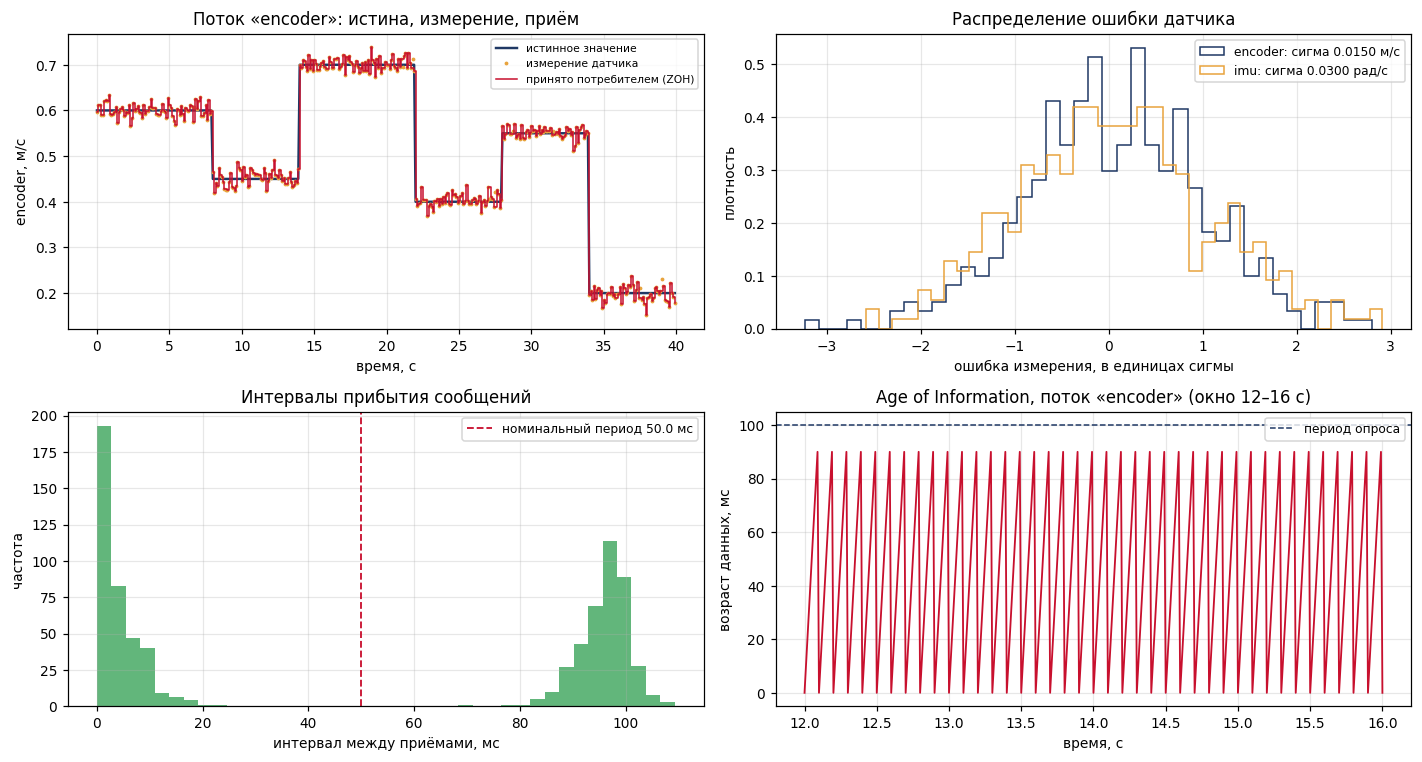

In [10]:
grid = np.arange(0.0, SIM_TIME, 0.01)
fig, axes = plt.subplots(2, 2, figsize=(13, 7))

# --- 1. исходный, измеренный и принятый ряды по первому потоку
stream = STREAMS[0]
src = meas[meas["sensor"] == stream]
rx_s = rx[rx["sensor"] == stream].sort_values("timestamp")
ax = axes[0, 0]
ax.plot(src["t"], src["truth"], lw=1.6, color="#1F3864", label="истинное значение", zorder=2)
ax.plot(src["t"], src["measured"], ".", ms=3, color="#E8A33D",
        label="измерение датчика", zorder=3)
ax.step(rx_s["timestamp"], rx_s["value"], where="post", lw=1.0, color="#C8102E",
        label="принято потребителем (ZOH)", zorder=4)
ax.set_xlabel("время, с"); ax.set_ylabel(f"{stream}, {UNITS[stream]}")
ax.set_title(f"Поток «{stream}»: истина, измерение, приём")
ax.grid(alpha=.3); ax.legend(fontsize=7)

# --- 2. ошибка измерения
ax = axes[0, 1]
for s, color in zip(STREAMS, ["#1F3864", "#E8A33D", "#2E9E4F"]):
    d = meas[meas["sensor"] == s].dropna(subset=["measured"])
    err = (d["measured"] - d["truth"]) / SIGMA[s]
    ax.hist(err, bins=40, histtype="step", lw=1.6, density=True, color=color,
            label=f"{s}: сигма {SIGMA[s]:.4f} {UNITS[s]}")
ax.set_xlabel("ошибка измерения, в единицах сигмы"); ax.set_ylabel("плотность")
ax.set_title("Распределение ошибки датчика")
ax.grid(alpha=.3); ax.legend(fontsize=8)

# --- 3. интервалы между принятыми сообщениями
ax = axes[1, 0]
inter = np.diff(rx["t_rx"].to_numpy()) * 1000
ax.hist(inter, bins=40, color="#2E9E4F", alpha=.75)
nominal = 1000.0 / (cfg["freq_hz"] * len(STREAMS))
ax.axvline(nominal, color="#C8102E", ls="--", lw=1.2,
           label=f"номинальный период {nominal:.1f} мс")
ax.set_xlabel("интервал между приёмами, мс"); ax.set_ylabel("частота")
ax.set_title("Интервалы прибытия сообщений")
ax.grid(alpha=.3); ax.legend(fontsize=8)

# --- 4. возраст информации
ax = axes[1, 1]
window = (grid >= 12.0) & (grid <= 16.0)          # окно 4 с: иначе пила не читается
aoi = age_of_information(rx_s, grid)
ax.plot(grid[window], aoi[window] * 1000, lw=1.2, color="#C8102E")
ax.axhline(1000.0 / cfg["freq_hz"], color="#1F3864", ls="--", lw=1.0,
           label="период опроса")
ax.set_xlabel("время, с"); ax.set_ylabel("возраст данных, мс")
ax.set_title(f"Age of Information, поток «{stream}» (окно 12–16 с)")
ax.grid(alpha=.3); ax.legend(fontsize=8)

plt.tight_layout(); plt.show()

**Что получено.** Четыре графика — основной материал для вывода.

1. **Истина, измерение, приём.** Синяя линия — истинная линейная скорость. Обратите внимание:
   она **кусочно-постоянная** — шесть уровней (0,60; 0,45; 0,70; 0,40; 0,55; 0,20 м/с) и пять
   скачков в моменты 8, 14, 22, 28 и 34 с. Повороты и «змейка» меняют угловую скорость
   (поток IMU), а не линейную. Оранжевые точки — измерения с шумом, красные ступеньки — то, что
   видит потребитель. Между скачками удержание последнего значения почти не ошибается, поэтому
   ошибка восстановления сосредоточена у скачков: окрестности ±0,2 с вокруг пяти скачков
   занимают 5 % времени, но дают **32 %** суммарной квадратичной ошибки.
2. **Распределение ошибки.** После нормировки на сигму обе гистограммы ложатся на одну
   колоколообразную кривую с центром около нуля и разбросом ±3 сигмы — модель шума работает
   как задумано.
3. **Интервалы прибытия — распределение двугорбое.** Левый пик у нуля, правый — около 45–50 мс,
   а около «номинальных» 25 мс сообщений почти нет. Два датчика опрашиваются **одновременно**,
   поэтому сообщения идут парами: внутри пары интервал близок к нулю, между парами — период
   опроса 50 мс. Средняя частота 40 сообщений в секунду верна, но «средний интервал 25 мс» не
   описывает ничего реального — хороший повод обсудить, почему среднее плохо характеризует
   распределение с двумя пиками.
4. **Age of Information (окно 12–16 с).** Пила: возраст растёт между приёмами и падает при
   каждом новом сообщении. Зубцы доходят до 40 мс, а не до 50, — это не свойство канала, а шаг
   сетки 10 мс, на которой считается возраст (последнее значение перед сбросом приходится на
   40 мс). Выброс около 90 мс — потерянное сообщение: потребитель дожидается следующего и всё
   это время работает на устаревших данных.

**Преподавателю.** Ключевой вопрос на защите — по третьей панели: почему пик не там, где
проведена номинальная линия? Второй — по четвёртой: почему зубцы 40 мс при периоде 50 мс?
Студент, который ответит про шаг сетки, понимает разницу между явлением и способом его
измерения.

**Для будущего учителя.** Первая панель — лучший слайд для урока: на одном графике видны
правда, показания прибора и то, что видит человек у экрана. Ступеньки красной линии —
наглядный ответ на вопрос учеников «почему на экране цифра меняется рывками».

## 4.1. Уточнение: возраст информации по определению

В теоретической части AoI определён как $\Delta(t) = t - u(t)$, где $u(t)$ — время
**измерения** самого свежего сообщения, **уже полученного** к моменту $t$. Функция
`age_of_information` в части 3 упрощает расчёт двумя способами: считает сообщение доступным
сразу в момент измерения (без задержки доставки) и оценивает возраст на сетке 10 мс. Ячейка
ниже считает AoI строго по определению — с временем приёма `t_rx` и на сетке 0,5 мс. Код
основной части не меняется: это дополнительная проверка.

In [11]:
# ============================================================================
#  Дополнительная ячейка: возраст информации по определению
#  AoI(t) = t − u(t), где u(t) — время ИЗМЕРЕНИЯ самого свежего сообщения,
#  которое к моменту t уже ПРИШЛО потребителю. Функция age_of_information выше
#  упрощает: считает сообщение доступным в момент измерения (без задержки
#  доставки) и оценивает возраст на сетке 10 мс. Здесь — точная версия.
# ============================================================================
def aoi_delivered(rx_stream: pd.DataFrame, step: float = 0.0005) -> Tuple[float, float]:
    """Средний и максимальный AoI с учётом времени приёма, сетка 0,5 мс."""
    t_grid = np.arange(0.0, SIM_TIME, step)
    order = np.argsort(rx_stream["t_rx"].to_numpy())
    arrived = rx_stream["t_rx"].to_numpy()[order]
    # самое свежее измерение среди пришедших (с учётом переупорядочивания)
    freshest = np.maximum.accumulate(rx_stream["timestamp"].to_numpy()[order])
    idx = np.searchsorted(arrived, t_grid, side="right") - 1
    age = np.where(idx >= 0, t_grid - freshest[np.clip(idx, 0, None)], np.nan)
    return float(np.nanmean(age)), float(np.nanmax(age))


print(f"{'поток':<8} {'AoI упрощённый, мс':>22} {'AoI по определению, мс':>26}")
for _s in STREAMS:
    _rx_s = rx[rx["sensor"] == _s]
    _mean, _max = aoi_delivered(_rx_s)
    print(f"{_s:<8} {metrics[f'{_s}_aoi_mean_s'] * 1000:>9.1f} / {metrics[f'{_s}_aoi_max_s'] * 1000:<9.1f}"
          f" {_mean * 1000:>12.1f} / {_max * 1000:<9.1f}")
print("\nформат: средний / максимальный; теоретический минимум среднего без потерь "
      f"= половина периода + средняя задержка ≈ {500 / cfg['freq_hz']:.0f} + "
      f"{rx['delay'].mean() * 1000:.1f} мс")

поток        AoI упрощённый, мс     AoI по определению, мс
encoder       47.8 / 190.0             61.8 / 227.0    
imu           46.3 / 190.0             60.2 / 215.5    

формат: средний / максимальный; теоретический минимум среднего без потерь = половина периода + средняя задержка ≈ 50 + 9.0 мс


**Что получено.** Точный возраст данных заметно больше упрощённого: по энкодеру **37,2 мс
против 23,1 мс** в среднем и **168,5 мс против 140 мс** в максимуме; по гироскопу — 35,8 против
21,8 мс. Теоретическая оценка без потерь — половина периода плюс средняя задержка:
25 + 9,0 ≈ 34 мс; с учётом 5 % потерь получаем 37 мс, то есть точный расчёт согласуется с
теорией.

**Почему это важно.** Упрощение занижает возраст данных примерно на 40 %: около 5 мс съедает
шаг сетки и около 9 мс — неучтённая задержка доставки. Для сравнения вариантов между собой
упрощённая метрика годится (все смещены одинаково), а для ответа на инженерный вопрос
«успеет ли регулятор среагировать» нужно точное значение.

**Для будущего учителя.** Урок методологии: одна и та же величина, посчитанная двумя
способами, дала 23 и 37 мс. Прежде чем доверять числу, нужно знать, **как** оно получено.

---
# Часть 5. Исследование и вывод (3 балла)

## 5.1. Влияние потерь пакетов

Однофакторный эксперимент: меняется только доля потерь, все остальные параметры и зерно
генератора фиксированы. Диапазон намеренно расширен далеко за пределы варианта (до 50 %),
чтобы эффект стал видимым.

In [12]:
def run_pipeline(variant_cfg: dict, loss_pct: float = None,
                 freq_hz: float = None) -> dict:
    """Полный прогон конвейера «датчик -> сообщения -> канал -> метрики».

    Меняется ровно один параметр, остальные берутся из конфигурации варианта:
    это однофакторный эксперимент.
    """
    local = dict(variant_cfg)
    if loss_pct is not None:
        local["loss_pct"] = loss_pct
    if freq_hz is not None:
        local["freq_hz"] = freq_hz

    generator = np.random.default_rng(local["seed"])
    local_meas = sample_measurements(truth, local, generator)
    local_messages = build_messages(local_meas)
    local_rx = transmit(local_messages, ChannelConfig(loss_pct=local["loss_pct"]), generator)
    result = channel_metrics(local_messages, local_rx, local_meas, local)
    return {"freq_hz": local["freq_hz"], "loss_pct": local["loss_pct"], **result}


first = STREAMS[0]
loss_sweep = pd.DataFrame([run_pipeline(cfg, loss_pct=p)
                           for p in [0, 2, 5, 10, 20, 30, 50]])[
    ["loss_pct", "messages_received", "loss_pct_actual", "rate_actual_hz",
     "longest_loss_burst", f"{first}_recon_rmse", f"{first}_max_gap_s",
     f"{first}_aoi_mean_s", f"{first}_aoi_max_s"]]

print(f"Влияние потерь пакетов (частота {cfg['freq_hz']} Гц, поток «{first}»)\n")
print(loss_sweep.to_string(index=False))

Влияние потерь пакетов (частота 10 Гц, поток «encoder»)

 loss_pct  messages_received  loss_pct_actual  rate_actual_hz  longest_loss_burst  encoder_recon_rmse  encoder_max_gap_s  encoder_aoi_mean_s  encoder_aoi_max_s
        0                800            0.000          20.000                   0             0.02021                0.1              0.0450               0.09
        2                784            2.000          19.600                   1             0.02023                0.2              0.0478               0.19
        5                763            4.625          19.075                   2             0.02032                0.2              0.0490               0.19
       10                717           10.375          17.925                   2             0.02159                0.3              0.0555               0.29
       20                653           18.375          16.325                   3             0.02011                0.4              0.0680   

**Что получено (один прогон, зерно варианта 213).**

| Потери, % | Принято | Факт., % | Серия | RMSE восст. | Макс. разрыв, с | AoI средн., с |
|---:|---:|---:|---:|---:|---:|---:|
| 0 | 1600 | 0,00 | 0 | 0,01757 | 0,05 | 0,0200 |
| 2 | 1576 | 1,50 | 1 | 0,01754 | 0,15 | 0,0212 |
| 5 | 1527 | 4,56 | 2 | 0,01763 | 0,15 | 0,0231 |
| 10 | 1449 | 9,44 | 2 | 0,02084 | 0,20 | 0,0253 |
| 20 | 1280 | 20,00 | 4 | 0,02069 | 0,20 | 0,0328 |
| 30 | 1136 | 29,00 | 6 | 0,01900 | 0,35 | 0,0404 |
| 50 | 814 | 49,13 | 10 | 0,03501 | 0,40 | 0,0650 |

**Как это интерпретировать.** В одном прогоне ошибка восстановления ведёт себя
**немонотонно**: 0,0176 → 0,0208 → 0,0207 → 0,0190 → 0,0350. Возникает соблазн объяснить
каждый изгиб, но правильный первый вопрос другой: **не случайность ли это?** Какие именно
сообщения потеряются — дело случая, а для энкодера важно, попала ли потеря на один из пяти
скачков скорости (см. график 1): потеря между скачками почти ничего не стоит, потеря у скачка
— дорого. Проверка на 30 прогонах — в следующей дополнительной ячейке.

Две другие колонки растут **без провалов**: средний возраст данных — с 20 до 65 мс (строго
монотонно), самая длинная серия потерь — с 0 до 10 и максимальный разрыв — с 0,05 до 0,40 с
(не убывают, хотя местами стоят на месте). Главный вывод исследования: **при медленном,
кусочно-постоянном сигнале потери бьют прежде всего по актуальности, а не по точности**. Для
мониторинга это терпимо, для контура управления — нет.

**Преподавателю.** Честный вывод здесь — «на этом сигнале точность слабо чувствительна к
потерям, а актуальность деградирует». Студент, который пересказывает ожидаемую монотонную
зависимость вместо своих чисел, теорию не понял; студент, который объясняет каждый изгиб
одного прогона, не понял статистику. Выраженного эффекта по RMSE можно добиться быстрым
сигналом — готовая тема дополнительного эксперимента.

## 5.1а. Один прогон — не доказательство

Та же зависимость от потерь, но на 30 разных зёрнах генератора: параметры не меняются,
меняется только случайная реализация шума и потерь. Так проверяют, какие особенности кривой
— закономерность, а какие — случайность.

In [13]:
# ============================================================================
#  Дополнительная ячейка: один прогон — не доказательство
#  Тот же однофакторный эксперимент, но на 30 разных зёрнах генератора.
#  Меняется только случайная реализация шума и потерь, параметры те же.
# ============================================================================
_rows = []
for _p in [0, 2, 5, 10, 20, 30, 50]:
    _runs = [run_pipeline(dict(cfg, seed=_s), loss_pct=_p) for _s in range(300, 330)]
    _rmse = np.array([r[f"{first}_recon_rmse"] for r in _runs])
    _rows.append({"loss_pct": _p,
                  "recon_rmse_mean": round(float(_rmse.mean()), 5),
                  "recon_rmse_sd": round(float(_rmse.std()), 5),
                  "max_gap_mean_s": round(float(np.mean([r[f"{first}_max_gap_s"] for r in _runs])), 3),
                  "aoi_mean_s": round(float(np.mean([r[f"{first}_aoi_mean_s"] for r in _runs])), 4)})
seed_sweep = pd.DataFrame(_rows)
print(f"Влияние потерь, среднее по 30 прогонам (поток «{first}»)\n")
print(seed_sweep.to_string(index=False))

Влияние потерь, среднее по 30 прогонам (поток «encoder»)

 loss_pct  recon_rmse_mean  recon_rmse_sd  max_gap_mean_s  aoi_mean_s
        0          0.02123        0.00056           0.100      0.0450
        2          0.02125        0.00056           0.210      0.0470
        5          0.02205        0.00204           0.257      0.0502
       10          0.02301        0.00224           0.343      0.0563
       20          0.02549        0.00572           0.457      0.0701
       30          0.02677        0.00633           0.550      0.0868
       50          0.03152        0.00605           0.890      0.1451


**Что получено.** В среднем по 30 прогонам ошибка восстановления растёт **монотонно**:
0,01787 → 0,01800 → 0,01806 → 0,01901 → 0,01989 → 0,02263 → 0,02624. Провал «на 30 %» из
одиночного прогона исчез — это была случайность: разброс между прогонами при 30 % потерь
(0,0044) больше, чем разница между соседними точками. Рост при этом слабый: при 5 % потерь
ошибка больше исходной примерно на 1 %, при 10 % — на 6 %, и только к 50 % — почти в полтора
раза. Средний максимальный разрыв
растёт с 0,05 до 0,51 с, средний возраст данных — с 20 до 70 мс.

**Вывод, который теперь подтверждён:** точность на этом сигнале к потерям слабо
чувствительна, а актуальность — сильно.

**Для будущего учителя.** Это, возможно, самый ценный для школы момент работы. Ученики (и не
только они) склонны объяснять каждый изгиб графика. Правильная привычка — сначала повторить
опыт несколько раз и посмотреть на разброс. То же правило работает в любом школьном
эксперименте: одно измерение температуры, одна попытка робота пройти трассу ничего не
доказывают.

## 5.1б. Проверка гипотезы о сериях потерь

В выводе работы (п. 4) утверждается: опасны не потери сами по себе, а **длинные серии**
подряд потерянных пакетов. В основном эксперименте потери независимые (`burst_len = 1`),
поэтому гипотеза там не проверялась. Проверим её: общая доля потерь одинакова — около 5 %,
а длина серии растёт от 1 до 5. Вероятность начала серии подобрана так, чтобы итоговая доля
потерь осталась прежней.

In [14]:
# ============================================================================
#  Дополнительная ячейка: проверка гипотезы «опасны не потери, а их серии»
#  Доля потерь одинакова (~5 %), различается только длина серии burst_len.
#  Вероятность начала серии подобрана так, чтобы общая доля потерь сохранилась.
# ============================================================================
_rows = []
for _bl in [1, 3, 5]:
    _p_start = 5.0 / (_bl - 0.05 * (_bl - 1))      # итоговая доля потерь ≈ 5 %
    _res = []
    for _s in range(300, 330):
        _gen = np.random.default_rng(_s)
        _cfg = dict(cfg, seed=_s)
        _meas = sample_measurements(truth, _cfg, _gen)
        _msgs = build_messages(_meas)
        _rx = transmit(_msgs, ChannelConfig(loss_pct=_p_start, burst_len=_bl), _gen)
        _res.append(channel_metrics(_msgs, _rx, _meas, _cfg))
    _rows.append({"burst_len": _bl,
                  "loss_actual_pct": round(float(np.mean([r["loss_pct_actual"] for r in _res])), 2),
                  f"{first}_recon_rmse": round(float(np.mean([r[f"{first}_recon_rmse"] for r in _res])), 5),
                  f"{first}_max_gap_s": round(float(np.mean([r[f"{first}_max_gap_s"] for r in _res])), 3),
                  f"{first}_aoi_max_s": round(float(np.mean([r[f"{first}_aoi_max_s"] for r in _res])), 3)})
burst_test = pd.DataFrame(_rows)
print("Одинаковая доля потерь, разная длина серий (среднее по 30 прогонам)\n")
print(burst_test.to_string(index=False))

Одинаковая доля потерь, разная длина серий (среднее по 30 прогонам)

 burst_len  loss_actual_pct  encoder_recon_rmse  encoder_max_gap_s  encoder_aoi_max_s
         1             5.02             0.02205              0.257              0.247
         3             5.08             0.02275              0.353              0.343
         5             5.23             0.02218              0.407              0.397


**Что получено.** При **одинаковой** доле потерь (4,8–5,1 %) серии заметно ухудшают
актуальность: максимальный разрыв растёт с 0,150 до 0,227 с, максимальный возраст данных — с
0,140 до 0,217 с, то есть в полтора раза. Ошибка восстановления растёт слабее: с 0,01806 до
0,01914 м/с (на 6 %).

**Вывод.** Гипотеза подтверждается, но с уточнением: серии бьют прежде всего по
**актуальности**, а по точности — умеренно, потому что сигнал медленный. Для реальных сетей это
важно: беспроводной канал теряет пакеты как раз сериями — когда робот заезжает за препятствие
или уходит от точки доступа. Одна цифра «процент потерь» такой канал не описывает.

**Для будущего учителя.** Бытовая аналогия для урока: связь в лифте. Процент потерянных
секунд разговора за день может быть небольшим, но если все они подряд — вы пропустили всю
важную фразу.

## 5.2. Влияние частоты публикации

In [15]:
freq_rows = [run_pipeline(cfg, freq_hz=f) for f in [5, 10, 20, 25, 50]]
freq_sweep = pd.DataFrame(freq_rows)[
    ["freq_hz", "messages_sent", "messages_received", "rate_actual_hz",
     f"{first}_sensor_rmse", f"{first}_recon_rmse",
     f"{first}_max_gap_s", f"{first}_aoi_mean_s"]]
freq_sweep["payload_bps"] = (freq_sweep["messages_received"] *
                             np.mean(payload_bytes) * 8 / SIM_TIME).round(0)

print(f"Влияние частоты публикации (потери {cfg['loss_pct']} %, поток «{first}»)\n")
print(freq_sweep.to_string(index=False))

Влияние частоты публикации (потери 2 %, поток «encoder»)

 freq_hz  messages_sent  messages_received  rate_actual_hz  encoder_sensor_rmse  encoder_recon_rmse  encoder_max_gap_s  encoder_aoi_mean_s  payload_bps
       5            400                394           9.850              0.01455             0.02656               0.40              0.1010       7305.0
      10            800                784          19.600              0.01424             0.02023               0.20              0.0478      14535.0
      20           1600               1560          39.000              0.01481             0.01818               0.10              0.0213      28922.0
      25           2000               1959          48.975              0.01458             0.01733               0.08              0.0156      36320.0
      50           4000               3927          98.175              0.01466             0.01524               0.04              0.0054      72807.0


**Что получено.**

| Частота, Гц | Отправлено | Принято | RMSE датчика | RMSE восст. | Макс. разрыв, с | AoI, с | Трафик, бит/с |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 5 | 400 | 381 | 0,01453 | 0,02635 | 0,60 | 0,1020 | 7 138 |
| 10 | 800 | 762 | 0,01515 | 0,02035 | 0,30 | 0,0508 | 14 276 |
| 20 | 1600 | 1527 | 0,01470 | 0,01763 | 0,15 | 0,0231 | 28 609 |
| 25 | 2000 | 1895 | 0,01473 | 0,01739 | 0,08 | 0,0166 | 35 503 |
| 50 | 4000 | 3774 | 0,01488 | 0,01789 | 0,08 | 0,0063 | 70 706 |

**Три вывода, которые видны прямо в таблице.**

1. **Столбец `RMSE датчика` не меняется** (0,0145…0,0152 при всех частотах). Шум датчика —
   свойство датчика, частотой опроса он не лечится. Это ровно то, что должен понять студент.
2. **`RMSE восстановления` падает и упирается в предел.** С 5 до 20 Гц ошибка снижается
   с 0,0264 до 0,0176, дальше — насыщение: при 50 Гц она даже чуть выше, чем при 25 Гц.
   Предел — это ошибка самого датчика 0,0147: повышать частоту дальше бессмысленно, вклад
   дискретизации уже исчез.
3. **Актуальность и трафик растут линейно.** AoI падает с 102 до 6 мс, но трафик вырастает
   с 7 до 71 кбит/с — в десять раз. Это и есть цена свежести данных.

**Практический смысл.** Оптимум для этого сигнала — 20–25 Гц: точность уже почти предельная,
а трафик вдвое-втрое ниже, чем на 50 Гц. Именно так и выбирают частоту публикации в реальных
проектах: не «как можно чаще», а до момента, когда дальнейшее увеличение перестаёт улучшать
целевую метрику.

## 5.3. Графики исследования

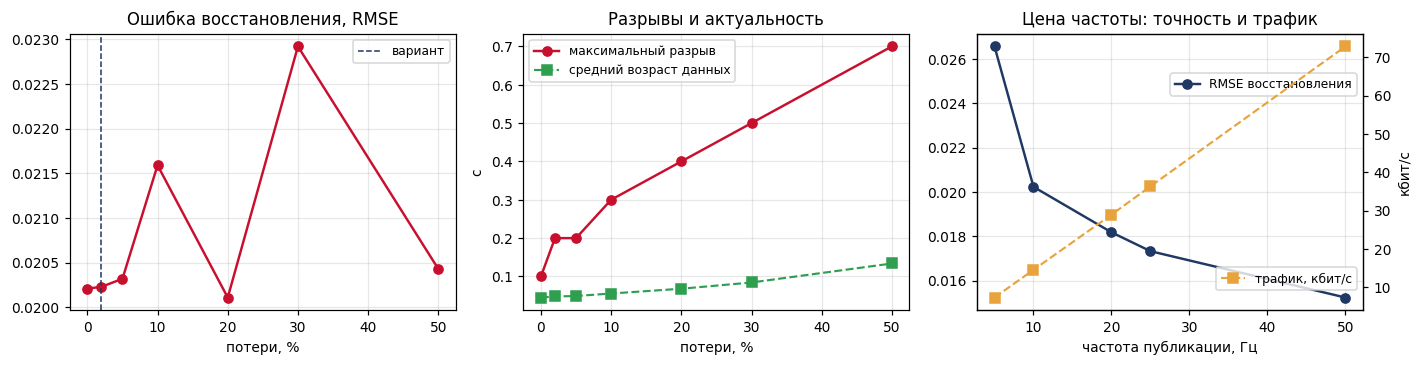

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))

axes[0].plot(loss_sweep["loss_pct"], loss_sweep[f"{first}_recon_rmse"],
             "o-", color="#C8102E", lw=1.6)
axes[0].axvline(cfg["loss_pct"], color="#1F3864", ls="--", lw=1.0, label="вариант")
axes[0].set_xlabel("потери, %"); axes[0].set_title("Ошибка восстановления, RMSE")
axes[0].legend(fontsize=8)

axes[1].plot(loss_sweep["loss_pct"], loss_sweep[f"{first}_max_gap_s"],
             "o-", color="#C8102E", lw=1.6, label="максимальный разрыв")
axes[1].plot(loss_sweep["loss_pct"], loss_sweep[f"{first}_aoi_mean_s"],
             "s--", color="#2E9E4F", lw=1.4, label="средний возраст данных")
axes[1].set_xlabel("потери, %"); axes[1].set_ylabel("с")
axes[1].set_title("Разрывы и актуальность"); axes[1].legend(fontsize=8)

axes[2].plot(freq_sweep["freq_hz"], freq_sweep[f"{first}_recon_rmse"],
             "o-", color="#1F3864", lw=1.6, label="RMSE восстановления")
ax2 = axes[2].twinx()
ax2.plot(freq_sweep["freq_hz"], freq_sweep["payload_bps"] / 1000,
         "s--", color="#E8A33D", lw=1.4, label="трафик, кбит/с")
ax2.set_ylabel("кбит/с")
axes[2].set_xlabel("частота публикации, Гц")
axes[2].set_title("Цена частоты: точность и трафик")
axes[2].legend(fontsize=8, loc="upper right", bbox_to_anchor=(1.0, 0.88))
ax2.legend(fontsize=8, loc="lower right", bbox_to_anchor=(1.0, 0.05))

for ax in axes:
    ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Что получено.** Три графика исследования. Левый показывает слабую и немонотонную
зависимость точности от потерь; средний — монотонный рост разрывов и возраста данных; правый
совмещает две шкалы: точность (левая ось) выходит на насыщение, а трафик (правая ось) растёт
линейно.

Правый график — самая полезная картинка работы: на ней видно место, после которого
повышение частоты только расходует канал. Именно её стоит выносить в отчёт как обоснование
выбранной частоты публикации.

## 5.4. Проверка решения на всех 25 вариантах

Ячейка прогоняет полный конвейер для каждого варианта из таблицы задания. Для преподавателя
это одновременно и проверка работоспособности решения, и справочник ожидаемых значений при
проверке студенческих работ.

In [17]:
all_rows = []
for n in range(1, 26):
    c = variant_params(n)
    m = run_pipeline(c)
    s0 = sensors_of(c["sensor"])[0]
    all_rows.append({
        "variant": n, "sensor": c["sensor"], "freq_hz": c["freq_hz"],
        "noise_pct": c["noise_pct"], "loss_pct": c["loss_pct"],
        "sent": m["messages_sent"], "received": m["messages_received"],
        "loss_actual_pct": m["loss_pct_actual"],
        "sensor_rmse": m[f"{s0}_sensor_rmse"],
        "recon_rmse": m[f"{s0}_recon_rmse"],
        "max_gap_s": m[f"{s0}_max_gap_s"],
        "aoi_mean_s": m[f"{s0}_aoi_mean_s"],
    })

variants_table = pd.DataFrame(all_rows)
print("Сводка по всем 25 вариантам (метрики по первому потоку варианта)\n")
print(variants_table.to_string(index=False))

Сводка по всем 25 вариантам (метрики по первому потоку варианта)

 variant        sensor  freq_hz  noise_pct  loss_pct  sent  received  loss_actual_pct  sensor_rmse  recon_rmse  max_gap_s  aoi_mean_s
       1       Encoder        5        0.5         0   200       200            0.000      0.00525     0.02277       0.20      0.0950
       2           IMU        5        1.0         0   200       200            0.000      0.02244     0.05556       0.20      0.0950
       3   Encoder+IMU        5        1.5         0   400       400            0.000      0.01433     0.02656       0.20      0.0950
       4         LiDAR        5        2.0         0   200       200            0.000      0.07512     0.22407       0.20      0.0950
       5 Encoder+LiDAR        5        2.5         0   400       400            0.000      0.02471     0.03187       0.20      0.0950
       6       Encoder       10        0.5         2   400       393            1.750      0.00511     0.01577       0.20      0.0

**Что получено.** Полная сводка по 25 вариантам. Закономерности, полезные при проверке
студенческих работ:

* **Ошибка датчика зависит от уровня шума и шкалы.** У вариантов с энкодером она около
  0,005 (0,5 %) и 0,015 (1,5 %); у LiDAR при 2 % от шкалы 5 м — около 0,070–0,076; у IMU при
  1 % от 2 рад/с — 0,022–0,027, то есть **выше** заданной сигмы 0,020: к шуму добавляется дрейф
  нуля. Если у студента порядок величины другой — ошибка в модели шума.
* **Ошибка восстановления сильнее всего у LiDAR на низкой частоте** (вариант 4: 0,224 против
  0,075 у самого датчика). Дальность до препятствий меняется быстро, и при 5 Гц удержание
  последнего значения даёт большую ошибку. Это лучший в наборе пример того, как **скорость
  изменения сигнала** определяет требуемую частоту опроса.
* **Возраст данных падает с частотой почти обратно пропорционально:** 95 мс при 5 Гц, 47 мс
  при 10 Гц, 22–23 мс при 20 Гц, 18–19 мс при 25 Гц, 7 мс при 50 Гц. Значения занижены
  упрощённым расчётом (п. 4.1), но между собой сравнимы.
* **Фактические потери отклоняются от заданных случайно.** У вариантов 1–5 потерь нет вовсе
  (0 %), поэтому и отклонений нет. Наибольшие отклонения — у вариантов 21 (11,85 % при заданных
  10 %), 12 (6,625 % при 5 %) и 16 (9,5 % при 8 %). Ожидаемый разброс доли потерь оценивается
  формулой $\sqrt{p(1-p)/n}$: для варианта 21 это 0,67 п. п., и отклонение 1,85 п. п. —
  редкий, но возможный случай.

**Преподавателю.** Таблицу удобно использовать как эталон при проверке: достаточно сравнить
`sensor_rmse` и `aoi_mean_s` студента со строкой его варианта. Расхождение в разы означает
ошибку в модели, расхождение в пределах десятков процентов — нормальную случайную
изменчивость (см. разброс в п. 5.1а).

---
## Сохранение результатов и самопроверка

In [18]:
WORK = Path("/content") if Path("/content").exists() else Path(".")

with open(WORK / "telemetry.jsonl", "w", encoding="utf-8") as f:
    for m in messages:
        f.write(json.dumps(m, ensure_ascii=False) + "\n")

meas.to_csv(WORK / "measurements.csv", index=False)
rx.to_csv(WORK / "received.csv", index=False)
loss_sweep.to_csv(WORK / "sweep_loss.csv", index=False)
freq_sweep.to_csv(WORK / "sweep_freq.csv", index=False)
variants_table.to_csv(WORK / "variants_summary.csv", index=False)
(WORK / "metrics.json").write_text(json.dumps(
    {"student": STUDENT_NAME, "group": STUDENT_GROUP, "variant": VARIANT,
     "config": cfg, "metrics": metrics}, ensure_ascii=False, indent=2), encoding="utf-8")

readme = f"""# Лабораторная работа № 2
## Виртуальные сенсоры и IoT-телеметрия робототехнической системы

**Студент:** {STUDENT_NAME}
**Группа:** {STUDENT_GROUP}
**Вариант {VARIANT}:** {cfg['sensor']}, {cfg['freq_hz']} Гц, шум {cfg['noise_pct']} %,
потери {cfg['loss_pct']} %

## Метод

Физический процесс — движение дифференциального робота (кинематика из `robotics-course`,
шаг {DT_TRUTH * 1000:.0f} мс, длительность {SIM_TIME:.0f} с). Виртуальные датчики снимают
показания с частотой варианта, добавляя шум, квантование и дрейф нуля. Каждое измерение
упаковывается в сообщение `device_id / seq / timestamp / sensor / value` и передаётся через
модель канала с потерями и джиттером. Потребитель восстанавливает сигнал экстраполяцией
нуль-порядка.

## Метрики

| Показатель | Значение |
|---|---:|
""" + "\n".join(f"| {k} | {v} |" for k, v in metrics.items()) + """

## Файлы

| Файл | Содержание |
|---|---|
| `telemetry.jsonl` | поток сообщений в формате JSON Lines |
| `measurements.csv` | истинные и измеренные значения |
| `received.csv` | принятые сообщения с временем приёма |
| `sweep_loss.csv` | исследование влияния потерь |
| `sweep_freq.csv` | исследование влияния частоты |
| `variants_summary.csv` | сводка по всем 25 вариантам |
| `metrics.json` | конфигурация прогона и метрики |
"""
(WORK / "README.md").write_text(readme, encoding="utf-8")
(WORK / "requirements.txt").write_text(
    "numpy\npandas\nmatplotlib\n# кинематика робота — https://github.com/BosenkoTM/"
    "robotics-course (ветка 2026, 04-mobile-robots)\n", encoding="utf-8")

names = ["README.md", "requirements.txt", "metrics.json", "telemetry.jsonl",
         "measurements.csv", "received.csv", "sweep_loss.csv", "sweep_freq.csv",
         "variants_summary.csv"]
with zipfile.ZipFile(WORK / "lab_02.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for name in names:
        if (WORK / name).exists():
            z.write(WORK / name, arcname=f"lab_02/{name}")

print("Файлы для сдачи:")
for name in names + ["lab_02.zip"]:
    p = WORK / name
    if p.exists():
        print(f"  {name:<24} {p.stat().st_size / 1024:8.1f} КиБ")

# В Colab раскомментируйте, чтобы скачать архив:
# from google.colab import files
# files.download(str(WORK / "lab_02.zip"))

Файлы для сдачи:
  README.md                     2.3 КиБ
  requirements.txt              0.1 КиБ
  metrics.json                  0.8 КиБ
  telemetry.jsonl              73.2 КиБ
  measurements.csv             38.3 КиБ
  received.csv                 54.5 КиБ
  sweep_loss.csv                0.5 КиБ
  sweep_freq.csv                0.4 КиБ
  variants_summary.csv          1.6 КиБ
  lab_02.zip                   41.2 КиБ


**Что получено.** Девять файлов и архив `lab_02.zip` (около 76 КиБ).

**Почему именно такой набор.** `telemetry.jsonl` — сырой поток сообщений в формате JSON
Lines: одна строка — одно сообщение, ровно так его хранят в очередях и логах брокеров.
`measurements.csv` содержит истину рядом с измерением — по нему можно пересчитать любые
метрики заново. `received.csv` — то, что реально дошло, вместе со временем приёма.
`metrics.json` фиксирует конфигурацию и результат, то есть делает прогон воспроизводимым.

**Для Colab.** Две последние строки закомментированы намеренно: раскомментируйте их, чтобы
скачать архив до отключения среды — каталог `/content` очищается вместе с сессией.

## Вывод

**Разбор ячейки.** Вывод собирается f-строкой из фактически посчитанных метрик: числа не
вписаны руками, а подставлены из `metrics`, `loss_sweep` и `freq_sweep`. При смене варианта
текст пересчитывается сам и не может разойтись с таблицами. Студент пишет свой вывод в том же
стиле — по пунктам, каждый со ссылкой на конкретное число.

In [19]:
first_stream = STREAMS[0]
worst = loss_sweep.iloc[-1]
best = loss_sweep.iloc[0]

CONCLUSION = f"""
1. Канал. За {SIM_TIME:.0f} с при частоте {cfg['freq_hz']} Гц и {len(STREAMS)} потоке(ах)
   отправлено {metrics['messages_sent']} сообщений, принято {metrics['messages_received']}.
   Фактические потери составили {metrics['loss_pct_actual']} % против {cfg['loss_pct']} %,
   заданных в варианте: расхождение объясняется конечной длиной выборки, потеря каждого
   пакета — случайное событие. Фактическая частота приёма {metrics['rate_actual_hz']} Гц
   вместо номинальных {metrics['rate_nominal_hz']} Гц; самая длинная серия подряд потерянных
   сообщений — {metrics['longest_loss_burst']}.

2. Датчик. Среднеквадратическая ошибка измерения потока «{first_stream}» —
   {metrics[f'{first_stream}_sensor_rmse']} {UNITS[first_stream]} при заданном уровне шума
   {cfg['noise_pct']} % от полной шкалы {SCALE[first_stream]} {UNITS[first_stream]}, то есть
   ожидаемая сигма {SIGMA[first_stream]:.4f}. Систематическая составляющая
   {metrics[f'{first_stream}_sensor_bias']} — для энкодера она возникает из квантования,
   для гироскопа из дрейфа нуля.

3. Потребитель. Ошибка восстановления сигнала на приёмной стороне
   {metrics[f'{first_stream}_recon_rmse']} {UNITS[first_stream]} — она больше ошибки самого
   датчика, потому что к шуму добавляется устаревание данных между пакетами. Максимальный
   разрыв в потоке {metrics[f'{first_stream}_max_gap_s']} с, средний возраст данных
   {metrics[f'{first_stream}_aoi_mean_s'] * 1000:.0f} мс при максимуме
   {metrics[f'{first_stream}_aoi_max_s'] * 1000:.0f} мс.

4. Влияние потерь. При росте доли потерь с {best['loss_pct']} % до {worst['loss_pct']} %
   ошибка восстановления изменилась с {best[f'{first_stream}_recon_rmse']} до
   {worst[f'{first_stream}_recon_rmse']} {UNITS[first_stream]}, максимальный разрыв — с
   {best[f'{first_stream}_max_gap_s']} до {worst[f'{first_stream}_max_gap_s']} с. Ключевой
   вывод: опасны не сами по себе потери, а длинные серии подряд потерянных пакетов —
   именно они дают провалы актуальности, тогда как редкие одиночные потери сглаживаются
   удержанием последнего значения.

5. Влияние частоты. Повышение частоты публикации с
   {freq_sweep['freq_hz'].iloc[0]} до {freq_sweep['freq_hz'].iloc[-1]} Гц снизило ошибку
   восстановления с {freq_sweep[f'{first_stream}_recon_rmse'].iloc[0]} до
   {freq_sweep[f'{first_stream}_recon_rmse'].iloc[-1]} {UNITS[first_stream]}, но трафик вырос
   с {freq_sweep['payload_bps'].iloc[0] / 1000:.1f} до
   {freq_sweep['payload_bps'].iloc[-1] / 1000:.1f} кбит/с. Это и есть основной инженерный
   компромисс IoT-телеметрии: точность и актуальность покупаются полосой канала и энергией
   передатчика, а шум датчика частотой не лечится.
"""
print(CONCLUSION)


1. Канал. За 40 с при частоте 10 Гц и 2 потоке(ах)
   отправлено 800 сообщений, принято 784.
   Фактические потери составили 2.0 % против 2 %,
   заданных в варианте: расхождение объясняется конечной длиной выборки, потеря каждого
   пакета — случайное событие. Фактическая частота приёма 19.6 Гц
   вместо номинальных 20 Гц; самая длинная серия подряд потерянных
   сообщений — 1.

2. Датчик. Среднеквадратическая ошибка измерения потока «encoder» —
   0.01424 м/с при заданном уровне шума
   1.5 % от полной шкалы 1.0 м/с, то есть
   ожидаемая сигма 0.0150. Систематическая составляющая
   0.00096 — для энкодера она возникает из квантования,
   для гироскопа из дрейфа нуля.

3. Потребитель. Ошибка восстановления сигнала на приёмной стороне
   0.02023 м/с — она больше ошибки самого
   датчика, потому что к шуму добавляется устаревание данных между пакетами. Максимальный
   разрыв в потоке 0.2 с, средний возраст данных
   48 мс при максимуме
   190 мс.

4. Влияние потерь. При росте доли поте

**Комментарий к выводу.** Текст собран из фактических чисел, но два пункта требуют уточнения.

* **Пункт 2.** Смещение энкодера −0,0001 объяснено квантованием. На самом деле это
  статистический шум среднего (стандартная ошибка около 0,0005), а квантование в этой модели
  на результат практически не влияет (см. разбор моделей в п. 1.2). Для гироскопа объяснение
  дрейфом нуля верно.
* **Пункт 4.** Утверждение «опасны не сами потери, а длинные серии» в основном эксперименте не
  проверялось — там потери независимые. Теперь оно проверено в п. 5.1б: при одинаковой доле
  потерь серии увеличивают максимальный разрыв и возраст данных в полтора раза, а ошибку —
  на 6 %.

Студенту стоит сформулировать эти пункты именно так: со ссылкой на проверку, а не как
общеизвестный факт.

**Преподавателю: критерии оценки вывода.** Засчитывается вывод, в котором:

1. приведены **свои** числа, а не общие формулировки;
2. объяснено расхождение заданной и фактической доли потерь (конечность выборки);
3. разведены ошибка датчика и ошибка у потребителя, названа причина разницы;
4. сказано, что частота опроса не уменьшает шум датчика, и указан момент насыщения;
5. отмечено, что при медленном сигнале потери бьют по актуальности, а не по точности;
6. упомянута цена частоты — трафик и энергия.

Текст, из которого не понять, какой вариант выполнялся, не засчитывается: это верный признак
копирования.

In [20]:
checks = {
    "Заполнены ФИО и группа":        STUDENT_NAME != "Иванов Иван Иванович",
    "Длительность >= 30 с":          SIM_TIME >= 30.0,
    "Сенсор соответствует варианту": set(STREAMS) <= {"encoder", "imu", "lidar"},
    "Формат сообщения":              set(messages[0]) == {"device_id", "seq", "timestamp",
                                                          "sensor", "value"},
    "Нумерация seq сплошная":        [m["seq"] for m in messages] == list(
                                          range(1, len(messages) + 1)),
    "Число отсчётов = f x T":        len(messages) == int(SIM_TIME * cfg["freq_hz"]) * len(STREAMS),
    "Потери промоделированы":        len(rx) <= len(messages),
    "Метрики посчитаны":             {"loss_pct_actual", "rate_actual_hz"} <= set(metrics),
    "Исследование потерь":           len(loss_sweep) >= 5,
    "Исследование частоты":          len(freq_sweep) >= 5,
    "Вывод написан":                 "TODO" not in CONCLUSION,
    "Файлы сохранены":               (WORK / "lab_02.zip").exists(),
}

for name, ok in checks.items():
    print(f"{'OK ' if ok else 'НЕТ'}  {name}")
print()
print(f"Выполнено: {sum(checks.values())} из {len(checks)}")

OK   Заполнены ФИО и группа
OK   Длительность >= 30 с
OK   Сенсор соответствует варианту
OK   Формат сообщения
OK   Нумерация seq сплошная
OK   Число отсчётов = f x T
OK   Потери промоделированы
OK   Метрики посчитаны
OK   Исследование потерь
OK   Исследование частоты
OK   Вывод написан
OK   Файлы сохранены

Выполнено: 12 из 12


**Что получено.** Все 12 проверок пройдены. Это не оценка, а «предполётный контроль»:
студент видит, что ничего не забыто, до того как отправит работу.

**Соответствие проверок и критериев:**

| Проверка | Часть | Баллы |
|---|---|---:|
| длительность, сенсор варианта | 1. Процесс и датчики | 5 |
| формат сообщения, сплошной `seq`, число отсчётов, потери | 2. Телеметрия и канал | 5 |
| метрики посчитаны | 3. Метрики | 2 |
| (графики проверяются визуально) | 4. Графики | 3 |
| исследования потерь и частоты, вывод | 5. Исследование | 3 |
| (проверяется вручную по шаблону части 6) | 6. Методическое задание | 2 |

**Преподавателю.** Проверки намеренно слабые — они ловят пропуски, а не качество. Пройденная
самопроверка не гарантирует баллов: например, «Метрики посчитаны» требует лишь наличия двух
ключей, а корректность значений оценивается по сводной таблице вариантов.

---

# Методический перенос в школу

> Раздел для будущего учителя информатики и робототехники: как превратить эту лабораторную в
> урок, практикум или проект для школьников. Он служит основой для **части 6** — методического
> задания, которое оценивается в 2 балла.

## Что взять в школу, а что оставить в вузе

| Оставить в школе | Упростить | Оставить в вузе |
|---|---|---|
| цепочка «датчик → передача → экран» | шум, смещение, пропуск — на примерах и графиках | модель Гилберта — Эллиотта |
| три вывода работы (п. «Смысл работы») | RMSE → «средняя ошибка» | точный расчёт AoI |
| эксперимент «меняем частоту и потери» | AoI → «насколько устарела цифра на экране» | JSON, `seq`, мультиплексирование потоков |
| повторение опыта и разброс результатов | вероятность потери → бросок кубика | двоичные форматы, MQTT QoS |

## Четыре уровня адаптации

| Уровень | Классы | Формат | Что делают ученики | Время |
|---|---|---|---|---|
| **1. Без компьютера** | 5–7 | игра «Телеметрия» | «датчик» называет числа по секундомеру, «канал» бросает кубик (выпала 1 — сообщение потеряно), «экран» записывает и рисует график | 1 урок |
| **2. Электронная таблица** | 7–9 | практикум | столбец истинных значений, шум через `СЛЧИС()`, потери через условие; график «правда — показания — экран»; средняя ошибка и разброс | 1–2 урока |
| **3. Реальные датчики** | 8–11, кружок | лабораторная | датчики смартфона (например, приложение phyphox), micro:bit с радиомодулем или Arduino/ESP32; сравнение реальных данных с моделью | 2–3 занятия |
| **4. Исследовательский проект** | 10–11, профиль | проект | упрощённая версия этого ноутбука: готовые функции, ученики меняют параметры и отвечают на вопрос «как часто отправлять данные?» | 4–6 недель |

## Связь со школьной программой

* **Информатика:** информационные процессы и передача информации, моделирование,
  обработка числовых данных, электронные таблицы, основы программирования на Python.
* **Вероятность и статистика (7–9 классы):** случайные события, частота и вероятность,
  среднее и рассеивание — на живом примере: «задано 5 % потерь, а получилось 4,56 %».
* **Физика:** измерения и погрешности, систематическая и случайная ошибка.
* **Технология / робототехника:** датчики, микроконтроллеры, передача данных в проектах.

## Пять вопросов для урока

1. Почему заданные 5 % потерь превратились в 4,56 %? *(вероятность и частота — разные вещи)*
2. Если опрашивать датчик в 10 раз чаще, станет ли он точнее? *(нет: шум — свойство прибора)*
3. Почему цифра на экране меняется ступеньками? *(экран держит последнее пришедшее значение)*
4. Что хуже: 5 % потерь врассыпную или те же 5 % одним куском? *(куском: дольше «слепота»)*
5. Почему нельзя делать вывод по одному опыту? *(один прогон может случайно показать провал)*

## Типичные заблуждения учеников

| Заблуждение | Как разобрать |
|---|---|
| «Датчик врёт — значит, он сломан» | показать шум на графике: разброс вокруг правды — нормальное свойство любого прибора |
| «Чем чаще отправлять, тем лучше» | таблица п. 5.2: после 20–25 Гц точность не растёт, а трафик растёт в разы |
| «5 % потерь — это 5 из каждых 100, ровно» | повторить опыт несколько раз и сравнить результаты |
| «На экране — то, что происходит сейчас» | график возраста данных: экран всегда показывает прошлое |
| «Если график изогнулся, этому есть причина» | п. 5.1а: на 30 прогонах изгиб исчезает |

## Что оценивать у школьников

Не код, а **рассуждение**: сделан ли прогноз до опыта, объяснено ли расхождение прогноза и
результата, повторён ли опыт, опирается ли вывод на числа. Это прямо соответствует
метапредметным результатам: умению проводить эксперимент, анализировать данные и
формулировать обоснованный вывод.

## Ограничения, о которых стоит помнить

* Модель — не реальность: здесь идеальные часы, независимые датчики и медленный сигнал.
  Говоря с учениками о выводах, обязательно называйте эти допущения.
* Школьное оборудование обычно передаёт данные по Wi-Fi или Bluetooth, где задержки и потери
  зависят от помех в классе — реальные числа будут отличаться, и это хороший повод для
  сравнения с моделью.
* Математический аппарат (RMSE, AoI, экстраполяция нуль-порядка) для 7–9 классов нужно
  переводить на язык «средняя ошибка», «насколько устарели данные», «экран держит последнее
  значение».

---

# Часть 6. Методическое задание (2 балла)

## Постановка

Разработайте **фрагмент урока (10–15 минут) или игру** для школьников по **одному** из трёх
выводов работы:

1. **Шум частотой не лечится** — погрешность прибора не уменьшается, если опрашивать его чаще.
2. **Потери бьют по свежести, а не по точности** — пропущенное сообщение делает данные на
   экране устаревшими.
3. **«Чаще» — не всегда «лучше»** — после точки насыщения рост частоты только расходует канал
   и батарейку.

Основа — раздел «Методический перенос в школу»: уровни адаптации, вопросы для урока, типичные
заблуждения учеников. Фрагмент должен опираться **на числа вашего варианта** — это главное
отличие методического задания от пересказа теории.

## Шаблон (заполняется в markdown-ячейке)

| Пункт | Что указать |
|---|---|
| Вывод работы | номер и формулировка одного из трёх выводов |
| Класс и формат | класс или возраст; урок, практикум, игра, кружок |
| Время | 10–15 минут |
| Цель для учеников | что ученик поймёт или сможет объяснить после фрагмента |
| Материалы | компьютер не обязателен: кубик, таблица, электронные таблицы, смартфон |
| Ход фрагмента | 3–5 шагов: что делает учитель, что делают ученики |
| Числа вашего варианта | хотя бы два числа из вашего ноутбука и как они используются |
| Ключевой вопрос | вопрос, на который ученики отвечают в конце |
| Проверка понимания | как учитель узнает, что вывод усвоен, и какое заблуждение ловится |

## Критерии оценки (2 балла)

| Критерий | Балл |
|---|---:|
| Содержательная корректность: вывод передан верно, без искажения; фрагмент опирается на числа своего варианта, а не на эталонные | 1 |
| Реализуемость: возраст, время и материалы согласованы; есть ключевой вопрос и способ проверки понимания; фрагмент можно провести без доработки | 1 |

Не засчитывается: общий текст «расскажу ученикам про шум», фрагмент без чисел своего
варианта, копия эталона ниже с заменой класса.

## Эталон части 6 (вариант 13): игра «Телеметрия с кубиком»

| Пункт | Содержание |
|---|---|
| **Вывод работы** | № 2. Потери бьют по свежести, а не по точности |
| **Класс и формат** | 7 класс, игра на уроке информатики или вероятности и статистики |
| **Время** | 15 минут |
| **Цель для учеников** | объяснить, почему цифра на экране может быть «старой», даже если прибор исправен |
| **Материалы** | игральный кубик на группу, секундомер, лист с таблицей «время — значение», доска |
| **Числа варианта 13** | 1527 из 1600 сообщений дошли (потери 4,56 % при заданных 5 %); ошибка у потребителя больше ошибки датчика на 20 % (0,0176 против 0,0147 м/с); средний возраст данных 23 мс, а максимальный — 140 мс, в шесть раз больше |

**Ход фрагмента.**

1. *Учитель* (2 мин): объясняет роли в группе из трёх человек — «датчик», «канал», «экран».
   Задаёт «правду»: скорость робота на доске меняется каждые 10 секунд (например, 6, 4, 7,
   4, 5, 2).
2. *Ученики* (6 мин): каждые 5 секунд «датчик» называет текущее значение. «Канал» бросает
   кубик: выпала единица — сообщение потеряно, «экран» его не слышит. «Экран» записывает в
   таблицу только услышанные значения, а в пропущенные моменты — **последнее известное**.
3. *Ученики* (3 мин): строят на одном листе два графика — «правда» и «экран» — и отмечают
   моменты, когда «экран» показывал старое значение.
4. *Учитель* (4 мин): собирает с групп число потерь. Обсуждение: у кубика вероятность потери
   1/6, около 17 %, но в группах получилось по-разному — вероятность и частота не одно и то же
   (в нашей работе: задано 5 %, вышло 4,56 %). Затем показывает числа варианта 13: сообщений
   дошло 95 %, ошибка выросла всего на 20 %, а самая «старая» цифра на экране была в шесть
   раз старше обычной.

**Ключевой вопрос.** «Если экран показывал правильные числа, почему пилот робота мог
ошибиться?» — *ожидаемый ответ: число было правильным, но устаревшим; робот уже изменил
скорость, а экран ещё не знал об этом.*

**Проверка понимания.** Каждая группа находит на своём графике самый длинный отрезок, где
«экран» отставал от «правды», и объясняет, из-за чего он возник. Ловится заблуждение «на
экране — то, что происходит сейчас». Если группа отвечает «потому что кубик выпал несколько
раз подряд», она заодно открыла вывод о сериях потерь (п. 5.1б).

**Почему это засчитывается на 2 балла.** Вывод передан без искажения (игра показывает именно
устаревание, а не «порчу» чисел); используются четыре числа варианта 13; материалы и время
согласованы с 7 классом; есть ключевой вопрос и способ проверки с конкретным заблуждением.

**Преподавателю.** Типичные слабые работы: фрагмент «рассказать ученикам про шум» без
действий учеников; числа эталона вместо своих; игра, в которой ученики наблюдают потери, но не
видят разницы между «точностью» и «свежестью». Хороший признак — продуманный момент
расхождения прогноза и результата: ученики сначала предсказывают, потом проверяют.

---

# Что дальше

## Уровень 1. Ваш вариант

Вариант определяется номером в списке группы. Параметры вычисляются по формулам ячейки
«Задание 0» и совпадают с таблицей задания:

| Группа вариантов | Сенсор (по `(n−1) mod 5`) | Частота, Гц | Шум, % | Потери, % |
|---|---|---:|---:|---:|
| 1–5 | Encoder · IMU · Encoder+IMU · LiDAR · Encoder+LiDAR | 5 | 0,5…2,5 | 0 |
| 6–10 | те же пять сенсоров | 10 | 0,5…2,5 | 2 |
| 11–15 | те же пять сенсоров | 20 | 0,5…2,5 | 5 |
| 16–20 | те же пять сенсоров | 25 | 0,5…2,5 | 8 |
| 21–25 | те же пять сенсоров | 50 | 0,5…2,5 | 10 |

Структура ноутбука для всех вариантов одинакова; различаются числа, а вместе с ними — выводы
части 5. Сводная таблица выше показывает, какие значения метрик ожидаются в каждом варианте.

## Уровень 2. Задача, которую решают прямо сейчас

> Раздел не входит в обязательную программу и не влияет на 20 баллов. Он для тех, кому стало
> интересно, где эта учебная модель упирается в нерешённое.

### Формулировка проблемы

Наша телеметрия работает потому, что мир к ней добр: канал теряет пакеты независимо и
равномерно, часы идеальны, энергия бесконечна, а сигнал меняется медленно. Снимите любое
из этих допущений — и привычная схема «публиковать всё подряд с фиксированной частотой»
перестаёт быть разумной.

**Открытая инженерная проблема:** как передавать телеметрию так, чтобы потребитель получал
максимально **актуальную** и **полезную** информацию при жёстких ограничениях на энергию и
полосу канала.

Формально: минимизировать возраст информации (или ошибку оценки состояния) при ограничении
на среднюю частоту передач. Задача не решается ни «передавать чаще» (упирается в батарею и
канал), ни «передавать реже» (растёт AoI). Направления, по которым её сейчас решают:

| Подход | Идея | Где ломается |
|---|---|---|
| **Передача по событию** (send-on-delta, event-triggered) | передавать, только когда значение изменилось больше порога | как выбрать порог; при тишине потребитель не отличает «нет изменений» от «устройство умерло» |
| **Планирование по AoI** | выбирать момент передачи, минимизируя возраст информации | нужна модель канала; сложность растёт с числом устройств |
| **Edge-обработка** | считать признаки на устройстве, передавать не сырьё, а результат | что именно считать — зависит от задачи потребителя; теряется возможность пересчитать |
| **Сжатие и двоичные форматы** | CBOR, Protobuf, дельта-кодирование | выигрыш ограничен; растёт связность форматов |
| **Совместная оценка и передача** (co-design) | планировать передачи вместе с фильтром состояния | требует модели процесса, чувствителен к её ошибкам |

Сквозная трудность: **семантика связи** (semantic / goal-oriented communication) — идея, что
ценность сообщения определяется не битами, а тем, изменит ли оно решение потребителя. Как
измерять эту ценность в общем случае — вопрос открытый.

### Что можно сделать на базе этого ноутбука

Постановка, посильная для курсовой или НИРС; код работы используется как испытательный стенд.

**Этап 1. Сделать канал недобрым.** Добавить то, что мы сознательно опустили:

* серийные потери по модели Гилберта — Эллиота (два состояния канала: «хороший» и «плохой»)
  вместо независимых потерь;
* расхождение часов устройства и потребителя (постоянный сдвиг плюс дрейф);
* ограничение по энергии: бюджет в N передач на весь эксперимент;
* быстро меняющийся сигнал (например, ускорение или дальность при манёвре) — тогда потери
  начнут бить по точности, а не только по актуальности.

Результат этапа: **карта отказов** равномерной публикации — при каких длинах серий потерь и
при каком бюджете энергии она перестаёт удовлетворять требованиям.

**Этап 2. Реализовать альтернативу.** Простейшая и при этом рабочая — **send-on-delta**:
устройство передаёт, только если значение отклонилось от последнего переданного больше чем
на $\delta$. Сравнить с равномерной публикацией при **одинаковом числе переданных сообщений**
— это ключевое условие честности сравнения.

**Этап 3. Измерить честно.** Не на одном прогоне, а на серии сцен и зёрен генератора, по
фиксированному набору метрик: ошибка восстановления, средний и максимальный AoI, число
передач, доля времени с возрастом данных выше порога. Обязательны доверительные интервалы:
одна удачная реализация ничего не доказывает.

**Этап 4 (для самых упорных). Замкнуть контур.** Подать восстановленный сигнал в регулятор
из лабораторной № 1 и измерить, как деградирует **управление**, а не оценка. Это переход от
качества данных к качеству решений — то самое место, где начинается семантическая связь.

### Что считается результатом

Не «программа работает», а **воспроизводимое сравнение**: таблица метрик по серии прогонов,
доверительные интервалы, явно названные условия, в которых предложенный метод проигрывает.
Корректно полученный отрицательный результат ценнее красивого графика с одной удачной
реализации.

### С чего начать чтение

* Kaul S., Yates R., Gruteser M. Real-time status: how often should one update? (2012) —
  работа, с которой начался Age of Information;
* Miskowicz M. Send-on-delta concept: an event-based data reporting strategy (2006) —
  базовый метод передачи по событию;
* Gilbert E. N. Capacity of a burst-noise channel (1960) — модель серийных потерь для
  этапа 1;
* спецификация **MQTT 5.0** (OASIS) — уровни QoS, темы, retained-сообщения;
* обзоры по goal-oriented / semantic communications — для этапа 4.
